# Sprint 03 · Project 3 — Emotion Classification with Attention

Self-contained Kaggle workflow: pinned real GoEmotions `simplified` → six-class preparation → bounded checks → four independent model workers → validation-frozen selection → final held-out evaluation → offline Gradio application and archives.

**Normal workflow:** import this notebook, enable **Internet**, select **GPU T4 ×2**, then **Save Version → Save & Run All**. A single allocated GPU also works. No other uploads or restart are required. Independent project directory: `/kaggle/working/emotion_classification_run/`.

This notebook defaults to **full** mode with the proposal’s original budget: recurrent models up to 10 epochs (Adam 0.001, batch 64); DistilBERT up to 3 epochs (AdamW 0.00002, batch 16, accumulation 1); patience 2. Hidden size 128, dropout 0.3, fine-tuned GloVe-50. It uses at most two GPUs allocated to this notebook and does not borrow GPUs from other projects.

**Recorded full-run evidence:** the executed Kaggle notebook `instant-sprint03-project03-emotionclassification.ipynb` and saved emotion archives document four-model CUDA training on two Tesla T4 GPUs, validation-frozen selection of DistilBERT, final held-out evaluation, attention/padding checks, CPU checkpoint reloads and Gradio interface construction. The results section below displays those saved observations and refreshes from the current run on Run All. Phase 1 changes address UTF-8 portability, provenance and results presentation; training was not repeated for these edits. An interactive or hosted app launch is not established by interface construction. Smoke metrics remain functional checks only; smoke never evaluates real test predictions.

**Kaggle runtime revision:** avoids ensurepip failure by seeding isolated virtualenv via host pip --python (with pip, setuptools, wheel, wrapt); forces MPLBACKEND=Agg across all standalone workers and stages; relaxes host PyTorch check to >=2.4; enables AMP GradScaler recovery for transient fp16 overflows; synchronized SHA256 integrity map.


## Audited real-data reference

The target order is exactly **joy, sadness, anger, fear, surprise, disgust**. Fine-grained label IDs come from the source metadata. Neutral-bearing rows and cross-emotion combinations are excluded. Same-group multilabel rows are retained. Duplicate connected groups use source IDs or NFC/whitespace/casefold full text; conflicts are removed, consistent groups prefer test → validation → train. No split reassignment occurs.

| Class | Train | Validation | Test |
|---|---:|---:|---:|
| joy | 15044 | 1929 | 1858 |
| sadness | 2313 | 266 | 283 |
| anger | 4283 | 555 | 572 |
| fear | 537 | 72 | 80 |
| surprise | 3845 | 459 | 488 |
| disgust | 495 | 61 | 76 |

Raw official split sizes: 43,410 / 5,426 / 5,427. Retained: **26,517 / 3,342 / 3,357**. Word and subword caps are both **128**, selected by the predeclared training p99.5 rule. Matched pretrained vocabulary rows: **17,320**. Token coverage: train 94.52%, validation 92.34%, test 92.29%. These are preparation observations, not predictive test metrics. Exact hashes and counts are embedded and must match on regeneration.

This is a filtered, leakage-controlled **GoEmotions-derived task**, not an unchanged benchmark. Published surprise includes confusion, curiosity and realization. Rare classes, English Reddit domain, sarcasm, label filtering, OOVs and truncation limit generalization.

## 1. Configuration and embedded runtime

Keep `MODE = "full"` for the final run. Optional `"smoke"` performs two optimizer steps per architecture on stratified training/validation samples; it creates conspicuously labeled demonstration archives and skips real test prediction. Environment overrides below exist for automated notebook verification, not normal setup.

Each embedded file is SHA-256 checked before use. Large assets are downloaded inside Kaggle, never embedded in this file.

In [ ]:
import os, sys, json, pathlib, hashlib, subprocess, importlib.util
MODE = os.environ.get("EMOTION_MODE", "full")
assert MODE in {"full", "smoke"}
BASE = pathlib.Path(os.environ.get("EMOTION_RUN_ROOT", "/kaggle/working/emotion_classification_run" if pathlib.Path("/kaggle/working").exists() else str(pathlib.Path.cwd() / "emotion_classification_run")))
BASE.mkdir(parents=True, exist_ok=True)
RUNTIME = BASE / "runtime"
RUNTIME.mkdir(exist_ok=True)
print("Mode:", MODE, "\nProject directory:", BASE)


In [ ]:
EMBEDDED_FILES = {'app.py': 'import os\nos.environ.setdefault(\'MPLBACKEND\',\'Agg\')\nos.environ.setdefault(\'USE_TF\',\'0\');os.environ.setdefault(\'USE_FLAX\',\'0\');os.environ.setdefault(\'TOKENIZERS_PARALLELISM\',\'false\')\nimport html,inspect,pathlib,re,torch\ntorch.set_num_threads(2)\nimport gradio as gr\nfrom common import LABELS\nfrom inference import Application\n\nEMOJI={\'joy\':\'😊\',\'sadness\':\'😢\',\'anger\':\'😠\',\'fear\':\'😨\',\'surprise\':\'😲\',\'disgust\':\'🤢\'}\nMODEL_NAMES={\'distilbert\':\'DistilBERT\',\'bilstm_attention\':\'BiLSTM + Attention\'}\nEXAMPLES=[\'I am so happy you made it!\',\'I am not happy about this.\',\'That is disgusting.\',\'Wait, what just happened?!\',\'😢😢\',\'happy happy sad happy\']\n\nTHEME=gr.themes.Base(primary_hue=\'indigo\',neutral_hue=\'slate\',radius_size=\'md\',\n    font=[gr.themes.GoogleFont(\'Instrument Sans\'),\'ui-sans-serif\',\'system-ui\',\'sans-serif\']\n).set(button_primary_background_fill=\'var(--ea)\',button_primary_background_fill_hover=\'var(--ea-hover)\',\n      button_primary_text_color=\'white\',button_primary_border_color=\'transparent\')\n\nCSS=\'\'\'\n@import url(\'https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:opsz,wght@12..96,600;12..96,700&display=swap\');\n:root{--ea:#5b43d6;--ea-hover:#4a33c0;--ea-soft:rgba(91,67,214,.10)}\n.dark{--ea:#a595ff;--ea-hover:#bbaeff;--ea-soft:rgba(165,149,255,.14)}\n.gradio-container{max-width:1040px!important;margin:0 auto!important;padding:40px 20px 56px!important}\n.e-head h1{font-family:\'Bricolage Grotesque\',\'Instrument Sans\',system-ui,sans-serif;font-weight:700;font-size:40px;line-height:1.05;letter-spacing:-.02em;margin:0 0 10px;color:var(--body-text-color)}\n.e-head p{max-width:62ch;font-size:17px;line-height:1.5;margin:0;color:var(--body-text-color-subdued)}\n.e-head{padding:0!important;border:0!important;background:none!important;box-shadow:none!important}\n.html-container{padding:0!important}\n.gradio-container .column{gap:14px!important}\n.e-input textarea{font-size:18px!important;line-height:1.5!important;background:transparent!important;box-shadow:none!important;border:0!important}\n.e-stretch,.e-stretch .prose,.e-stretch .html-container{height:100%;background:transparent!important;border:0!important;box-shadow:none!important;overflow:visible!important}\n.e-actions{gap:10px!important;align-items:center}\n.e-actions button{flex:0 0 auto!important;width:auto!important;min-width:0!important}\n.e-chips{gap:8px!important}\n.e-chips button{flex:0 0 auto!important;width:auto!important;min-width:0!important;background:transparent!important;border:1px solid var(--border-color-primary)!important;color:var(--body-text-color)!important;font-weight:400!important;border-radius:999px!important}\n.e-chips button:hover{border-color:var(--ea)!important;background:var(--ea-soft)!important}\n.e-try{margin:6px 0 0;font-size:14px;color:var(--body-text-color-subdued)}\n.e-card{border:1px solid var(--border-color-primary);border-radius:14px;padding:24px 26px;background:var(--background-fill-primary);height:100%;box-sizing:border-box}\n.e-card h2{font-family:\'Bricolage Grotesque\',\'Instrument Sans\',system-ui,sans-serif;font-size:20px;font-weight:600;letter-spacing:-.01em;margin:0 0 4px;color:var(--body-text-color)}\n.e-sub{margin:0 0 18px;font-size:14px;color:var(--body-text-color-subdued);line-height:1.45}\n.e-empty{color:var(--body-text-color-subdued);font-size:15px;line-height:1.5;margin:0}\n.e-result{display:flex;align-items:baseline;gap:14px;margin:6px 0 22px}\n.e-emoji{font-size:34px;line-height:1;align-self:center}\n.e-word{font-family:\'Bricolage Grotesque\',\'Instrument Sans\',system-ui,sans-serif;font-size:46px;font-weight:700;letter-spacing:-.02em;line-height:1;color:var(--ea)}\n.e-conf{font-size:18px;color:var(--body-text-color-subdued);font-variant-numeric:tabular-nums}\n.e-row{display:grid;grid-template-columns:84px 1fr 44px;align-items:center;gap:12px;margin:9px 0;font-size:15px;color:var(--body-text-color-subdued)}\n.e-row.win{color:var(--body-text-color);font-weight:600}\n.e-track{height:10px;border-radius:5px;background:color-mix(in srgb,var(--body-text-color) 8%,transparent);overflow:hidden}\n.e-fill{height:100%;border-radius:5px;background:color-mix(in srgb,var(--body-text-color) 28%,transparent)}\n.e-row.win .e-fill{background:var(--ea)}\n.e-pct{text-align:right;font-variant-numeric:tabular-nums}\n.e-badge{display:inline-block;padding:2px 10px;border-radius:999px;font-size:13px;font-weight:600;margin-left:6px;background:var(--ea-soft);color:var(--ea)}\n.e-badge.diff{background:color-mix(in srgb,#d98200 16%,transparent);color:#a86400}\n.dark .e-badge.diff{color:#ffb84d}\n.e-tokens{font-size:20px;line-height:1.3;margin:4px 0 6px}\n.e-tok{display:inline-flex;flex-direction:column;align-items:stretch;margin:0 8px 8px 0;cursor:default}\n.e-t{padding:0 1px;color:var(--body-text-color)}\n.e-bw{display:flex;align-items:flex-end;height:26px;border-bottom:1px solid var(--border-color-primary)}\n.e-b{display:block;width:100%;background:var(--ea);border-radius:2px 2px 0 0}\n.e-top{margin:14px 0 0;font-size:15px;color:var(--body-text-color)}\n.e-note{margin:8px 0 0;font-size:13px;line-height:1.45;color:var(--body-text-color-subdued)}\n.e-about{border:0!important;background:none!important}\n.e-about button,.e-about .label-wrap{padding-left:0!important}\n.e-about .block{overflow:visible!important}\n\'\'\'\n\ndef pct(p):\n    if p<0.005:return \'<1%\'\n    if p>0.995:return \'>99%\'\n    return f\'{p*100:.0f}%\'\n\ndef empty_card(title,hint):\n    return f\'<div class="e-card"><h2>{title}</h2><p class="e-empty">{hint}</p></div>\'\n\ndef prediction_card(r):\n    probs=sorted(r[\'probabilities\'].items(),key=lambda kv:-kv[1])\n    top,topp=probs[0]\n    model=MODEL_NAMES.get(r[\'selected_model\'],r[\'selected_model\'])\n    rows=\'\'.join(f\'<div class="e-row{" win" if i==0 else ""}" data-emotion="{html.escape(k)}" data-probability="{p:.10f}"><span>{html.escape(k)}</span><span class="e-track"><span class="e-fill" style="display:block;width:{p*100:.2f}%"></span></span><span class="e-pct">{pct(p)}</span></div>\' for i,(k,p) in enumerate(probs))\n    return (f\'<div class="e-card"><h2>Prediction</h2><p class="e-sub">From {html.escape(model)}. Probabilities are uncalibrated.</p>\'\n            f\'<div class="e-result"><span class="e-emoji">{EMOJI.get(top,"")}</span><span class="e-word">{html.escape(top.capitalize())}</span><span class="e-conf">{pct(topp)}</span></div>{rows}</div>\')\n\ndef attention_card(r):\n    agree=r[\'attention_prediction\']==r[\'prediction\']\n    badge=f\'<span class="e-badge{"" if agree else " diff"}">{"Agrees" if agree else "Disagrees"} with the prediction</span>\'\n    m=re.search(r\'uses (\\d+) of (\\d+) subwords\',r[\'attention_status\'])\n    extra=f\' The main model read only the first {m.group(1)} of {m.group(2)} subwords.\' if m and m.group(1)!=m.group(2) else \'\'\n    sub=f\'BiLSTM + Attention predicts <b>{html.escape(r["attention_prediction"])}</b>.{badge}{extra}\'\n    return f\'<div class="e-card"><h2>What the attention model looked at</h2><p class="e-sub">{sub}</p>{r["attention_html"]}</div>\'\n\nABOUT=\'\'\'Attention weights show where this one model put its focus. They are an inspection aid, not proof that a word caused the prediction. Hover a token to see its exact weight.\n\nThere is no neutral or mixed-emotion class, so text without a clear emotion still gets pushed into one of the six. The result describes the text, not the writer\'s mental state.\n\nInput is lowercased for the attention model. Long inputs are cut at a fixed length, and the card tells you when that happens.\'\'\'\n\ndef build(root=None):\n    application=Application(root or pathlib.Path(__file__).parent)\n    def classify(text):\n        try:r=application.run(text)\n        except ValueError as e:raise gr.Error(str(e))\n        return prediction_card(r),attention_card(r)\n    blocks_options = {\'theme\': THEME, \'css\': CSS} if \'theme\' in inspect.signature(gr.Blocks).parameters else {}\n    html_options = {\'padding\': False} if \'padding\' in inspect.signature(gr.HTML).parameters else {}\n    with gr.Blocks(title=\'Six Emotions + Attention\',fill_width=False,**blocks_options) as demo:\n        gr.HTML(\'<h1>Six Emotions + Attention</h1><p>Paste some English text. One model picks the emotion it expresses, and a second model shows which words it weighted most.</p>\',elem_classes=\'e-head\',**html_options)\n        if application.manifest[\'mode\']!=\'full\':gr.Markdown(\'**Smoke checkpoints: this is a functional demo only. The results say nothing about model quality.**\')\n        text=gr.Textbox(show_label=False,lines=3,placeholder=\'How does this text express emotion?\',elem_classes=\'e-input\')\n        with gr.Row(elem_classes=\'e-actions\'):\n            button=gr.Button(\'Classify\',variant=\'primary\',size=\'md\');clear=gr.Button(\'Clear\',variant=\'secondary\',size=\'md\')\n        gr.HTML(\'<p class="e-try">Or try one of these</p>\',**html_options)\n        with gr.Row(elem_classes=\'e-chips\'):\n            chips=[gr.Button(ex,size=\'sm\',variant=\'secondary\') for ex in EXAMPLES]\n        with gr.Row(equal_height=True):\n            with gr.Column(scale=2,min_width=340):pred=gr.HTML(empty_card(\'Prediction\',\'The emotion and its probability appear here.\'),**html_options,elem_classes=\'e-stretch\')\n            with gr.Column(scale=3,min_width=340):attn=gr.HTML(empty_card(\'What the attention model looked at\',\'Each word gets a bar showing how much weight the model gave it.\'),**html_options,elem_classes=\'e-stretch\')\n        with gr.Accordion(\'About these results\',open=False,elem_classes=\'e-about\'):gr.Markdown(ABOUT)\n        outs=[pred,attn]\n        button.click(classify,text,outs);text.submit(classify,text,outs)\n        for chip,ex in zip(chips,EXAMPLES):chip.click(lambda ex=ex:ex,None,text).then(classify,text,outs)\n        clear.click(lambda:(\'\',empty_card(\'Prediction\',\'The emotion and its probability appear here.\'),empty_card(\'What the attention model looked at\',\'Each word gets a bar showing how much weight the model gave it.\')),None,[text,pred,attn])\n    return demo\n\ndef launch(root=None):\n    demo = build(root)\n    parameters = inspect.signature(demo.launch).parameters\n    options = {\'theme\': THEME, \'css\': CSS} if \'theme\' in parameters else {}\n    if \'footer_links\' in parameters:\n        options[\'footer_links\'] = []\n    return demo.launch(**options)\n\nif __name__==\'__main__\':launch()\n', 'bootstrap.py': '"""Isolate project packages while retaining the host\'s CUDA-enabled PyTorch."""\nimport hashlib, json, os, pathlib, subprocess, sys, venv\n\nos.environ[\'MPLBACKEND\'] = \'Agg\'\n\ndef setup(root, requirements, mode=\'full\'):\n    root = pathlib.Path(root)\n    root.mkdir(parents=True, exist_ok=True)\n    runtime = root / \'isolated_runtime\'\n    python = runtime / (\'Scripts/python.exe\' if os.name == \'nt\' else \'bin/python\')\n    probe_code = """import torch,importlib.util,importlib.metadata,json,pathlib\nitems={}\nfor name in [\'torch\',\'torchgen\',\'functorch\',\'triton\',\'nvidia\',\'cuda\']:\n s=importlib.util.find_spec(name)\n if s:\n  locations=list(s.submodule_search_locations or [])\n  if locations:items[name]=locations[0]\ndist={}\nfor name in [\'torch\',\'triton\']:\n try:dist[name]=str(importlib.metadata.distribution(name)._path)\n except importlib.metadata.PackageNotFoundError:pass\nfor d in importlib.metadata.distributions():\n name=d.metadata.get(\'Name\',\'\').lower()\n if name.startswith((\'nvidia-\',\'cuda-\',\'pytorch-triton\')):dist[name]=str(d._path)\nprint(json.dumps({\'packages\':items,\'distributions\':dist,\'torch\':torch.__version__,\'compiled_cuda\':torch.version.cuda,\'gpu_count\':torch.cuda.device_count()}))\n"""\n    try:\n        host = json.loads(subprocess.check_output([sys.executable, \'-c\', probe_code], text=True))\n    except subprocess.CalledProcessError as error:\n        raise RuntimeError(\'The notebook host must provide working Kaggle CUDA PyTorch. On Kaggle enable GPU T4 x2 and rerun.\') from error\n    raw_version = host[\'torch\'].split(\'+\')[0].split(\'.\')[:2]\n    version = tuple(int(x) for x in raw_version)\n    if version < (2, 4):\n        raise RuntimeError(\'Host PyTorch >=2.4 is required for safe checkpoint loading; observed \' + host[\'torch\'])\n    if mode == \'full\' and host[\'gpu_count\'] < 1:\n        raise RuntimeError(\'Full mode requires an allocated GPU. Select Kaggle GPU T4 x2; one allocated GPU also works. Smoke is available for CPU verification.\')\n    if not python.exists():\n        venv.EnvBuilder(with_pip=False, system_site_packages=False).create(runtime)\n        # Pre-seed a safe sitecustomize in isolated site-packages so Python startup\n        # doesn\'t fall back to host\'s unshielded /usr/lib/python3.13/sitecustomize.py\n        # before wrapt is installed.\n        for sp in list(runtime.glob(\'lib/python*/site-packages\')) + list(runtime.glob(\'Lib/site-packages\')):\n            (sp / \'sitecustomize.py\').write_text(\'try:\\n    import wrapt\\nexcept ImportError:\\n    pass\\n\')\n        print(\'Seeding isolated pip without ensurepip; host packages are preserved.\', flush=True)\n        subprocess.run([sys.executable, \'-m\', \'pip\', \'--python\', str(python), \'install\',\n                        \'--disable-pip-version-check\', \'pip==25.3\', \'setuptools==80.9.0\', \'wheel==0.45.1\', \'wrapt==1.17.3\'], check=True)\n    site = pathlib.Path(subprocess.check_output([str(python), \'-c\', \'import sysconfig;print(sysconfig.get_paths()["purelib"])\'], text=True).strip())\n    # Ensure sitecustomize.py is present in the resolved site directory\n    sc_file = site / \'sitecustomize.py\'\n    if not sc_file.exists():\n        sc_file.write_text(\'try:\\n    import wrapt\\nexcept ImportError:\\n    pass\\n\')\n    for name, path in {**host[\'packages\'], **{pathlib.Path(p).name: p for p in host[\'distributions\'].values()}}.items():\n        target = site / name\n        if target.is_symlink():\n            target.unlink()\n        if not target.exists():\n            target.symlink_to(path, target_is_directory=True)\n    env = os.environ.copy()\n    env.update(MPLBACKEND=\'Agg\', USE_TF=\'0\', USE_FLAX=\'0\', TOKENIZERS_PARALLELISM=\'false\', OMP_NUM_THREADS=\'2\', MKL_NUM_THREADS=\'2\', OPENBLAS_NUM_THREADS=\'2\', PYTHONNOUSERSITE=\'1\')\n    dependencies = pathlib.Path(requirements)\n    marker = root / \'runtime_install_identity.json\'\n    key = hashlib.sha256((dependencies.read_text() + json.dumps(host, sort_keys=True)).encode()).hexdigest()\n    if not marker.exists() or json.loads(marker.read_text())[\'key\'] != key:\n        log = root / \'runtime_install.log\'\n        print(\'Installing isolated emotion dependencies; details: \' + str(log), flush=True)\n        with open(log, \'w\') as f:\n            subprocess.run([str(python), \'-m\', \'pip\', \'install\', \'--disable-pip-version-check\', \'-r\', str(dependencies)], env=env, stdout=f, stderr=subprocess.STDOUT, check=True)\n        marker.write_text(json.dumps({\'key\': key, \'host_torch\': host}, indent=2))\n    subprocess.run([str(python), \'-m\', \'pip\', \'check\'], env=env, check=True)\n    subprocess.run([str(python), \'-c\', "import torch,gradio,pyarrow,matplotlib;from transformers import Trainer,TrainingArguments,AutoTokenizer,AutoModelForSequenceClassification;import accelerate;print(\'Isolated imports passed; torch\',torch.__version__,\'CUDA\',torch.version.cuda,\'visible GPUs\',torch.cuda.device_count())"], env=env, check=True)\n    return str(python), env, host\n', 'common.py': '"""Shared, versioned emotion preprocessing. No learned state outside train."""\nimport hashlib, json, os, re, unicodedata, pathlib, random, time\n\nLABELS = [\'joy\', \'sadness\', \'anger\', \'fear\', \'surprise\', \'disgust\']\nMODELS = [\'distilbert\', \'lstm\', \'gru\', \'bilstm_attention\']\nPREPROCESS_VERSION = \'emotion-nfc-whitespace-v1-word-contraction-punct-v1\'\n# Preserve contractions, punctuation, redaction markers and each emoji code point.\nTOKEN_RE = re.compile(r"\\[[A-Za-z_]+\\]|\\w+(?:[\'’]\\w+)*|[^\\w\\s]", re.UNICODE)\ndef clean(text):\n    if not isinstance(text, str): return \'\'\n    return \' \'.join(unicodedata.normalize(\'NFC\', text).split())\ndef tokens(text): return TOKEN_RE.findall(clean(text).lower())\ndef identity(text): return clean(text).casefold()\ndef digest(obj):\n    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False,separators=(\',\',\':\')).encode()).hexdigest()\ndef sha(path):\n    h=hashlib.sha256()\n    with open(path,\'rb\') as f:\n        for b in iter(lambda:f.read(1024*1024),b\'\'): h.update(b)\n    return h.hexdigest()\ndef read(path): return json.loads(pathlib.Path(path).read_text(encoding=\'utf-8\'))\ndef write(path,obj):\n    p=pathlib.Path(path); p.parent.mkdir(parents=True,exist_ok=True)\n    tmp=p.with_suffix(p.suffix+\'.tmp\'); tmp.write_text(json.dumps(obj,indent=2,ensure_ascii=False,allow_nan=False),encoding=\'utf-8\'); tmp.replace(p)\ndef rows(path):\n    with open(path,encoding=\'utf-8\') as f: return [json.loads(x) for x in f if x.strip()]\ndef write_rows(path,records):\n    with open(path,\'w\',encoding=\'utf-8\') as f:\n        for r in records: f.write(json.dumps(r,ensure_ascii=False)+\'\\n\')\ndef seed_all(seed):\n    random.seed(seed)\n    import numpy as np, torch\n    np.random.seed(seed); torch.manual_seed(seed)\n    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)\ndef encode(text,vocab,cap):\n    ts=tokens(text)\n    return [vocab.get(t,1) for t in ts[:cap]],ts[:cap],len(ts)>cap\ndef validate_mapping(mapping,names):\n    if set(mapping)!=set(LABELS): raise ValueError(\'Mapping targets changed\')\n    flattened=[x for v in mapping.values() for x in v]\n    if len(flattened)!=len(set(flattened)) or set(flattened)!=(set(names)-{\'neutral\'}):\n        raise ValueError(\'Unknown or multiply mapped fine-grained labels\')\n    return {x:k for k,v in mapping.items() for x in v}\ndef classify(raw_labels,names,mapping,text):\n    if not isinstance(raw_labels,list) or any(type(i) is not int or i<0 or i>=len(names) for i in raw_labels):\n        raise ValueError(\'Unexpected label schema/ID\')\n    source=[names[i] for i in raw_labels]\n    if not clean(text) or not tokens(text): return None,\'unusable_text\',source\n    if not source: return None,\'empty_labels\',source\n    if \'neutral\' in source: return None,\'neutral\',source\n    mapped={mapping[n] for n in source}\n    if len(mapped)!=1: return None,\'cross_emotion\',source\n    return LABELS.index(next(iter(mapped))),\'candidate\',source\ndef dependencies():\n    import importlib.metadata as m, platform\n    versions={p:m.version(p) for p in [\'torch\',\'numpy\',\'pandas\',\'pyarrow\',\'scikit-learn\',\'transformers\',\'accelerate\',\'huggingface-hub\',\'tokenizers\',\'safetensors\',\'matplotlib\',\'gradio\']}\n    versions[\'python\']=platform.python_version(); return versions\ndef file_manifest(root):\n    root=pathlib.Path(root)\n    return {str(p.relative_to(root)):sha(p) for p in sorted(root.rglob(\'*\')) if p.is_file() and \'__pycache__\' not in str(p) and p.name!=\'files_manifest.json\'}\ndef verify_manifest(root):\n    root=pathlib.Path(root); manifest=read(root/\'files_manifest.json\')\n    for name,expected in manifest.items():\n        if not (root/name).is_file() or sha(root/name)!=expected: raise RuntimeError(\'Artifact identity mismatch: \'+name)\n', 'config.json': '{\n  "project": "emotion_classification_run",\n  "seed": 42,\n  "vocab_limit": 30000,\n  "embedding_dim": 50,\n  "hidden": 128,\n  "attention_dim": 128,\n  "dropout": 0.3,\n  "rnn_lr": 0.001,\n  "transformer_lr": 2e-05,\n  "rnn_epochs": 10,\n  "transformer_epochs": 3,\n  "patience": 2,\n  "rnn_batch": 64,\n  "transformer_batch": 16,\n  "transformer_accumulation": 1,\n  "clip": 1.0,\n  "cpu_threads": 2,\n  "tie_tolerance": 0.001,\n  "mode": "full",\n  "smoke_train_per_class": 4,\n  "smoke_validation_per_class": 2,\n  "smoke_steps": 2,\n  "length_policy": "train_p995_128_or_256",\n  "test_policy": "one frozen final evaluation per compatible full run"\n}', 'delivery.py': '"""Frozen validation selection, final test phase, reports and offline bundles."""\nimport json,os,pathlib,shutil,subprocess,sys,time,zipfile\nimport numpy as np,pandas as pd\nfrom common import *\nfrom inference import load_model,predict,Application\nfrom metrics import summary,plot_results\n\ndef select(root,modelroot,mode):\n    root=pathlib.Path(root);modelroot=pathlib.Path(modelroot);cfg=read(root/\'prepared/config.json\')\n    results={kind:read(modelroot/kind/\'result.json\') for kind in MODELS}\n    best=max(r[\'validation\'][\'macro_f1\'] for r in results.values())\n    tied=[kind for kind in MODELS if results[kind][\'validation\'][\'macro_f1\']>=best-cfg[\'tie_tolerance\']]\n    selected=min(tied,key=lambda k:(results[k][\'trainable_parameters\'],results[k][\'validation_end_to_end_seconds_per_record\'],MODELS.index(k)))\n    key=digest({k:sha(modelroot/k/\'files_manifest.json\') for k in MODELS})\n    selection={\'mode\':mode,\'selected\':selected,\'attention_model\':\'bilstm_attention\',\'validation_macro_f1\':{k:r[\'validation\'][\'macro_f1\'] for k,r in results.items()},\n               \'tie_policy\':\'Within 0.001 absolute of highest validation macro F1: fewer trainable parameters, then validation end-to-end latency, then fixed model order.\',\n               \'tied_candidates\':tied,\'frozen_before_test\':True,\'model_key\':key,\'quality_claim\':mode==\'full\'}\n    path=modelroot.parent/\'selection.json\'\n    if path.exists() and read(path)[\'model_key\']==key:\n        old=read(path)\n        if old[\'selected\']!=selected:raise RuntimeError(\'Frozen selection mismatch\')\n        return old\n    selection[\'frozen_unix\']=time.time();write(path,selection)\n    return selection\n\ndef final_evaluate(root,modelroot,selection,mode):\n    if mode!=\'full\':return {\'status\':\'skipped\',\'reason\':\'Smoke/bounded runs never evaluate real held-out test predictions.\'}\n    root=pathlib.Path(root);modelroot=pathlib.Path(modelroot);dest=root/\'reports/final_test\';dest.mkdir(parents=True,exist_ok=True)\n    frozen=read(modelroot.parent/\'selection.json\')\n    if frozen!=selection or not frozen[\'frozen_before_test\']:raise RuntimeError(\'Selection must be frozen before test evaluation\')\n    import torch\n    device=\'cuda\' if torch.cuda.is_available() else \'cpu\';torch.set_num_threads(2)\n    # Descriptive test audit already happened; predictive test outcomes begin only here.\n    records=rows(root/\'prepared/test.jsonl\');cfg=read(root/\'prepared/config.json\');vocab=read(root/\'prepared/vocab.json\')\n    all_results={}\n    for kind in MODELS:\n        item=dest/kind;item.mkdir(exist_ok=True)\n        key=digest({\'selection\':selection,\'test_records\':read(root/\'reports/reference_observed.json\')[\'split_fingerprints\'][\'test\'],\'checkpoint\':sha(modelroot/kind/\'files_manifest.json\')})\n        if (item/\'completed.json\').exists() and read(item/\'completed.json\')[\'key\']==key:\n            verify_manifest(item);all_results[kind]=read(item/\'metrics.json\');continue\n        if (item/\'started.json\').exists():\n            raise RuntimeError(\'An interrupted final test phase needs inspection: \'+str(item)+\'. Completed models are reusable; do not silently repeat a held-out claim.\')\n        write(item/\'started.json\',{\'key\':key,\'started_unix\':time.time(),\'policy\':\'no test-driven retuning or winner replacement\'})\n        model,tok=load_model(kind,modelroot/kind,root/\'tokenizer\',device)\n        p,_=predict(model,kind,[r[\'text\'] for r in records],vocab,cfg,tok,device,batch=32 if device==\'cuda\' else 4)\n        report=summary([r[\'target\'] for r in records],p);np.save(item/\'probabilities.npy\',p);write(item/\'metrics.json\',report);plot_results(report,item,kind)\n        subword_lengths=None\n        if kind==\'distilbert\':subword_lengths=[len(x) for x in tok([clean(r[\'text\']) for r in records],truncation=False)[\'input_ids\']]\n        groups={\'negation\':[],\'has_vocab_oov\':[],\'recurrent_truncated\':[],\'transformer_truncated\':[],\'fear\':[],\'disgust\':[]}\n        predictions=p.argmax(1);errors=[]\n        for i,r in enumerate(records):\n            ts=tokens(r[\'text\'])\n            if any(t in {\'not\',\'no\',\'never\',\'neither\',\'nor\'} or t.endswith(("n\'t",\'n’t\')) for t in ts):groups[\'negation\'].append(i)\n            if any(t not in vocab for t in ts):groups[\'has_vocab_oov\'].append(i)\n            if len(ts)>cfg[\'word_cap\']:groups[\'recurrent_truncated\'].append(i)\n            if subword_lengths is not None and subword_lengths[i]>cfg[\'subword_cap\']:groups[\'transformer_truncated\'].append(i)\n            if LABELS[r[\'target\']] in [\'fear\',\'disgust\']:groups[LABELS[r[\'target\']]].append(i)\n            if predictions[i]!=r[\'target\']:errors.append({**r,\'predicted\':LABELS[int(predictions[i])],\'probabilities\':p[i].tolist()})\n        slices={k:{\'records\':len(ix),\'metrics\':summary([records[i][\'target\'] for i in ix],p[ix]) if ix else None} for k,ix in groups.items()}\n        write(item/\'error_slices.json\',slices);write_rows(item/\'errors.jsonl\',errors)\n        write(item/\'completed.json\',{\'key\':key,\'finished_unix\':time.time()});write(item/\'files_manifest.json\',file_manifest(item));all_results[kind]=report\n        del model\n        if device==\'cuda\':torch.cuda.empty_cache()\n    write(root/\'reports/final_test_summary.json\',all_results)\n    narrative=[\'# Frozen held-out error analysis\',\'Selection remains \'+selection[\'selected\']+\'. These outcomes do not trigger retuning or winner replacement.\']\n    for kind,report in all_results.items():\n        narrative.append(\'\\n## \'+kind)\n        for label in [\'fear\',\'disgust\']:\n            r=report[\'classification_report\'][label]\n            narrative.append(f"{label}: support={int(r[\'support\'])}, precision={r[\'precision\']:.4f}, recall={r[\'recall\']:.4f}, F1={r[\'f1-score\']:.4f}. Interpret with the reported small support.")\n        cm=np.asarray(report[\'confusion_matrix\']);pairs=sorted(((int(cm[i,j]),i,j) for i in range(6) for j in range(6) if i!=j),reverse=True)[:5]\n        narrative.append(\'Largest confusions (true → predicted): \'+\', \'.join(f\'{LABELS[i]} → {LABELS[j]}: {n}\' for n,i,j in pairs)+\'.\')\n        slices=read(dest/kind/\'error_slices.json\')\n        for label in [\'negation\',\'has_vocab_oov\',\'recurrent_truncated\',\'transformer_truncated\']:\n            item=slices[label]\n            narrative.append(f"{label}: {item[\'records\']} records"+(f", accuracy {item[\'metrics\'][\'accuracy\']:.4f}, six-label macro F1 {item[\'metrics\'][\'macro_f1\']:.4f}." if item[\'metrics\'] else \'; no observed examples (or not applicable to this architecture).\'))\n        narrative.append(\'These are descriptive slices, not causal effects; their class mixtures differ. Inspect errors.jsonl for wording, ambiguity and possible sarcasm rather than assigning those explanations automatically.\')\n    narrative.append(\'\\nThe single-label filter excludes neutral-bearing and cross-emotion comments. Performance applies to the retained subset; the app still forces neutral/mixed text into six labels. Surprise includes curiosity/confusion/realization. Same-class encoding collisions are disclosed in data_audit.json; zero full-text overlap does not imply zero encoded overlap. No calibration or causal attention claim is made.\')\n    (root/\'reports/ERROR_ANALYSIS.md\').write_text(\'\\n\\n\'.join(narrative))\n    return all_results\n\ndef export_application(root,modelroot,selected,destination,mode):\n    root=pathlib.Path(root);modelroot=pathlib.Path(modelroot);dest=pathlib.Path(destination)\n    if dest.exists():shutil.rmtree(dest)\n    dest.mkdir(parents=True)\n    source=pathlib.Path(__file__).parent\n    for name in [\'common.py\',\'models.py\',\'inference.py\',\'download_models.py\',\'app.py\']:shutil.copy2(source/name,dest/name)\n    shutil.copy2(root/\'prepared/config.json\',dest/\'config.json\');shutil.copy2(root/\'prepared/vocab.json\',dest/\'vocab.json\');shutil.copytree(root/\'tokenizer\',dest/\'tokenizer\')\n    for kind in set([selected,\'bilstm_attention\']):\n        target=dest/\'models\'/kind;target.mkdir(parents=True)\n        names=[\'config.json\',\'model.safetensors\'] if kind==\'distilbert\' else [\'best.pt\']\n        for name in names:shutil.copy2(modelroot/kind/name,target/name)\n    write(dest/\'application.json\',{\'selected\':selected,\'attention_model\':\'bilstm_attention\',\'labels\':LABELS,\'mode\':mode,\'quality_claim\':mode==\'full\',\n          \'preparation_identity\':read(root/\'preparation_key.json\'),\'checkpoint_roles\':\'Selected model supplies bars; BiLSTM + Attention supplies its own separately labeled prediction and token weights.\',\n          \'cpu_parity_tolerance\':\'3e-6 CPU-to-CPU; 3e-3 CUDA-to-CPU probabilities, matching argmax on fixed validation probes required\',\n          \'no_dataset_or_glove_download_at_startup\':True})\n    (dest/\'requirements.txt\').write_text(\'torch>=2.6,<3\\nnumpy==2.2.6\\ntransformers==4.57.1\\naccelerate==1.11.0\\nhuggingface-hub==0.36.0\\ntokenizers==0.22.1\\nsafetensors==0.6.2\\ngradio==5.49.1\\nplotly==6.3.1\\nsocksio==1.0.0\\n\',encoding=\'utf-8\')\n    shutil.copy2(source/\'source_lock.json\',dest/\'source_lock.json\')\n    (dest/\'README.md\').write_text("# Emotion classification application\\n\\nSelected classifier: {selected}. Attention model: bilstm_attention. Mode: {mode}.\\n\\nUse Python 3.11 or 3.12, install with `pip install -r requirements.txt`, then\\n`python app.py`. A complete local bundle runs offline. A source-only checkout\\nretrieves missing inference assets from the default HF snapshot. No dataset or\\nfull GloVe download is performed. Hosting is a separate action.\\n\\nDefault repo: `Solayman-Sameh/emotion-classification-with-attention`.\\nDefault revision: `ee5352751c317e37e609630db3b8db0f5febd25e`.\\nDefault cache: `~/.cache/emotion_models`.\\n\\nOverride with `EMOTION_HF_REPO_ID`, `EMOTION_HF_REVISION`, or\\n`EMOTION_MODEL_CACHE`. A different repo defaults to `main` unless a revision is\\nsupplied. Private repos use `hf auth login` or the host\'s `HF_TOKEN`.\\n\\nPreload: `python download_models.py`. Check cache: `python download_models.py --offline`.\\n\\nLocal files are checked first, then the HF cache. Cache misses trigger downloads;\\nall files use one resolved commit and are hash-verified. A mismatch stops loading.\\nWeights are not copied into another cache. Transformers reads resolved local\\nassets with remote code disabled; app code comes from this checkout.\\n\\nBars are uncalibrated selected-model probabilities. The heatmap shows the separate\\nattention model\'s own prediction and normalized token weights. Neutral/mixed text\\nis forced into six labels. Notices and provenance are in `licenses/` and\\n`source_lock.json`.\\n".format(selected=selected,mode=mode),encoding=\'utf-8\')\n    licenses=dest/\'licenses\';licenses.mkdir()\n    for name in [\'README.md\',\'goemotions_LICENSE\',\'distilbert__README.md\',\'distilbert__LICENSE\']:\n        path=root/\'sources\'/name\n        if path.exists():shutil.copy2(path,licenses/name)\n    write(dest/\'files_manifest.json\',file_manifest(dest));return dest\n\ndef application_checks(destination,report_path):\n    dest=pathlib.Path(destination).resolve();application=Application(dest)\n    samples=[\'happy happy happy!\',"I am not happy about this.",\'😢😢\',\'x\',\'happy \'*160,\'<script>alert(1)</script>\']\n    expected=[application.run(text) for text in samples]\n    for text,result in zip(samples,expected):\n        assert list(result[\'probabilities\'])==LABELS and len(result[\'probabilities\'])==6\n        assert np.isclose(sum(result[\'attention\']),1,atol=1e-6)\n        assert \'<script>\' not in result[\'attention_html\']\n    for blank in [\'\', \' \\n\\t\']:\n        try:application.run(blank)\n        except ValueError:pass\n        else:raise AssertionError(\'Blank app input accepted\')\n    probe=dest.parent/(dest.name+\'_probe.json\');write(probe,{\'samples\':samples})\n    code="import sys;sys.path.insert(0,sys.argv[1]);from common import read,write;from inference import Application;a=Application(sys.argv[1]);write(sys.argv[2],[a.run(x) for x in read(sys.argv[3])[\'samples\']])"\n    out=dest.parent/(dest.name+\'_reload.json\')\n    env=os.environ.copy();env.update(CUDA_VISIBLE_DEVICES=\'\',HF_HUB_OFFLINE=\'1\',TRANSFORMERS_OFFLINE=\'1\',OMP_NUM_THREADS=\'2\',MKL_NUM_THREADS=\'2\',USE_TF=\'0\',USE_FLAX=\'0\')\n    subprocess.run([sys.executable,\'-c\',code,str(dest),str(out),str(probe)],env=env,check=True)\n    actual=read(out)\n    for e,a in zip(expected,actual):\n        assert e[\'prediction\']==a[\'prediction\'] and e[\'attention_prediction\']==a[\'attention_prediction\']\n        assert np.allclose(list(e[\'probabilities\'].values()),list(a[\'probabilities\'].values()),atol=3e-6)\n        assert np.allclose(e[\'attention\'],a[\'attention\'],atol=3e-6)\n    # Construct Gradio interface without opening a port or publishing.\n    subprocess.run([sys.executable,\'-c\',"import sys;sys.path.insert(0,sys.argv[1]);from app import build;demo=build(sys.argv[1]);assert demo is not None;print(\'Gradio build passed\')",str(dest)],env=env,check=True)\n    result={\'status\':\'passed\',\'selected\':application.manifest[\'selected\'],\'roles\':sorted(application.loaded),\'blank_rejected\':True,\'six_ordered_bars\':True,\n            \'edge_inputs\':samples,\'fresh_process_cpu_reload\':True,\'offline_startup\':True,\'attention_order_and_occurrences\':True,\'html_escaped\':True,\'gradio_build\':True,\'probability_tolerance\':3e-6}\n    write(report_path,result);return result\n\ndef curves(root,modelroot):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    reports=pathlib.Path(root)/\'reports\'\n    for kind in MODELS:\n        result=read(pathlib.Path(modelroot)/kind/\'result.json\');history=result[\'history\']\n        fig,axes=plt.subplots(1,2,figsize=(10,3))\n        if kind==\'distilbert\':\n            losses=[r for r in history if \'loss\' in r];scores=[r for r in history if \'eval_macro_f1\' in r]\n            axes[0].plot([r.get(\'epoch\',r[\'step\']) for r in losses],[r[\'loss\'] for r in losses],marker=\'o\')\n            axes[1].plot([r.get(\'epoch\',r[\'step\']) for r in scores],[r[\'eval_macro_f1\'] for r in scores],marker=\'o\')\n        else:\n            axes[0].plot([r[\'epoch\'] for r in history],[r[\'train_loss\'] for r in history],marker=\'o\')\n            axes[1].plot([r[\'epoch\'] for r in history],[r[\'validation_macro_f1\'] for r in history],marker=\'o\')\n        axes[0].set_title(\'Training loss\');axes[1].set_title(\'Validation macro F1\')\n        for ax in axes:ax.set_xlabel(\'Epoch\')\n        fig.suptitle(kind+\' — \'+result[\'mode\']);fig.tight_layout();fig.savefig(reports/(kind+\'_curves.png\'));plt.close(fig)\n        plot_results(result[\'validation\'],reports,kind+\'_validation\')\n\ndef zip_tree(source,dest):\n    source=pathlib.Path(source)\n    with zipfile.ZipFile(dest,\'w\',compression=zipfile.ZIP_DEFLATED,compresslevel=3) as archive:\n        for p in sorted(source.rglob(\'*\')):\n            if p.is_file() and \'__pycache__\' not in str(p):archive.write(p,str(p.relative_to(source)))\n    with zipfile.ZipFile(dest) as archive:\n        bad=archive.testzip()\n        if bad:raise RuntimeError(\'Archive CRC failure: \'+bad)\n    return {\'file\':str(dest),\'bytes\':pathlib.Path(dest).stat().st_size,\'sha256\':sha(dest)}\n\ndef package(root,modelroot,selection,mode):\n    root=pathlib.Path(root);modelroot=pathlib.Path(modelroot);reports=root/\'reports\';artifacts=root/\'artifacts\';artifacts.mkdir(exist_ok=True)\n    appdir=root/(\'application\' if mode==\'full\' else \'smoke_application\')\n    export_application(root,modelroot,selection[\'selected\'],appdir,mode);application_checks(appdir,reports/\'application_checks.json\')\n    app=Application(appdir);val=rows(root/\'prepared/validation.jsonl\')\n    html=[\'<!DOCTYPE html><meta charset="utf-8"><title>BiLSTM attention inspection</title><h1>Validation attention examples</h1><p>Actual normalized additive weights. Not causal explanations.</p>\']\n    for target in range(6):\n        text=next(r[\'text\'] for r in val if r[\'target\']==target);r=app.run(text)\n        import html as h\n        html.append(\'<h2>\'+h.escape(LABELS[target])+\'</h2><p>\'+h.escape(r[\'attention_status\'])+\'</p>\'+r[\'attention_html\'])\n    (reports/\'attention_examples.html\').write_text(\'\\n\'.join(html))\n    curves(root,modelroot)\n    comparison=[]\n    for kind in MODELS:\n        r=read(modelroot/kind/\'result.json\');comparison.append({\'model\':kind,\'mode\':mode,\'validation_accuracy\':r[\'validation\'][\'accuracy\'],\'validation_macro_f1\':r[\'validation\'][\'macro_f1\'],\n             \'train_seconds\':r[\'train_seconds\'],\'best_epoch\':r[\'best_epoch\'],\'trainable_parameters\':r[\'trainable_parameters\'],\'checkpoint_bytes\':sum(info[\'bytes\'] for info in r[\'checkpoint_files\'].values()),\n             \'peak_cuda_allocated_bytes\':r[\'peak_cuda_allocated_bytes\'],\'validation_e2e_seconds_per_record\':r[\'validation_end_to_end_seconds_per_record\']})\n        if mode==\'full\':\n            test=read(reports/\'final_test\'/kind/\'metrics.json\');comparison[-1].update(test_accuracy=test[\'accuracy\'],test_macro_f1=test[\'macro_f1\'])\n    pd.DataFrame(comparison).to_csv(reports/\'model_comparison.csv\',index=False)\n    write(reports/\'selection.json\',selection);write(reports/\'source_lock.json\',read(pathlib.Path(__file__).parent/\'source_lock.json\'))\n    write(reports/\'environment.json\',read(root/\'preparation_identity.json\'))\n    (reports/\'RESULTS_README.md\').write_text(\'# Experiment outputs\\n\\nMode: \'+mode+\'. \'+(\'Full training: validation selection was frozen before the held-out test phase.\' if mode==\'full\' else \'Functional smoke run only. Tiny training/validation metrics do not measure model quality. The real test set was not predictively evaluated.\')+\'\\n\\nConfusion matrices and class support are reported separately. Review fear/disgust supports, negation/OOV/truncation slices, and errors.jsonl before interpreting overall scores. Mixed emotions and neutral are excluded from training; the app has no neutral/mixed class. Published mapping broadens surprise to include cognitive labels. Attention and directionality differ between baselines, so improvements cannot be attributed solely to attention. Calibration and causal importance are not established. Concurrent timings are not isolated benchmarks.\\n\\nCode, dependencies, source revisions, hashes, preprocessing and exact record identities are persisted. Interrupted models restart; compatible completed models can be reused. No optimizer-state resume is claimed.\\n\')\n    experiment=root/\'experiment_export\'\n    if experiment.exists():shutil.rmtree(experiment)\n    experiment.mkdir();shutil.copytree(modelroot,experiment/\'models\');shutil.copytree(reports,experiment/\'reports\');shutil.copytree(root/\'tokenizer\',experiment/\'tokenizer\')\n    shutil.copy2(root/\'prepared/config.json\',experiment/\'config.json\');shutil.copy2(root/\'prepared/vocab.json\',experiment/\'vocab.json\')\n    for name in [\'selection.json\',modelroot.name+\'_schedule.json\']:\n        p=modelroot.parent/name\n        if p.exists():shutil.copy2(p,experiment/name)\n    for p in modelroot.parent.glob(modelroot.name+\'_schedule_history_*.json\'):shutil.copy2(p,experiment/p.name)\n    logdir=modelroot.parent/(modelroot.name+\'_logs\')\n    if logdir.exists():shutil.copytree(logdir,experiment/\'worker_logs\')\n    shutil.copytree(pathlib.Path(__file__).parent,experiment/\'runtime\',ignore=shutil.ignore_patterns(\'__pycache__\'))\n    write(experiment/\'files_manifest.json\',file_manifest(experiment))\n    prefix=\'emotion\' if mode==\'full\' else \'emotion_SMOKE_NO_QUALITY_CLAIM\'\n    outputs=[zip_tree(reports,artifacts/(prefix+\'_reports.zip\')),zip_tree(experiment,artifacts/(prefix+\'_four_model_experiment.zip\')),zip_tree(appdir,artifacts/(prefix+\'_trained_application.zip\'))]\n    write(artifacts/\'archive_manifest.json\',outputs);return outputs\n\n', 'inference.py': '"""Inference with verified local artifacts first and Hugging Face cache fallback."""\nimport html, pathlib, time\nimport numpy as np, torch\nfrom common import LABELS,clean,tokens,encode,read,verify_manifest\nfrom models import load_recurrent\nfrom download_models import resolve_model_root\n\ndef load_model(kind,path,tokenizer_path,device=\'cpu\',repo_id=None,revision=None,cache_dir=None):\n    path=pathlib.Path(path)\n    tokenizer_path=pathlib.Path(tokenizer_path)\n    needed=[path/\'config.json\',path/\'model.safetensors\',tokenizer_path/\'tokenizer.json\',tokenizer_path/\'tokenizer_config.json\'] if kind==\'distilbert\' else [path/\'best.pt\']\n    if not all(item.is_file() for item in needed):\n        root=resolve_model_root(path.parent.parent,repo_id=repo_id,revision=revision,cache_dir=cache_dir)\n        path=root/\'models\'/kind;tokenizer_path=root/\'tokenizer\'\n    if kind==\'distilbert\':\n        from transformers import AutoTokenizer,AutoModelForSequenceClassification\n        tok=AutoTokenizer.from_pretrained(tokenizer_path,local_files_only=True,trust_remote_code=False)\n        model=AutoModelForSequenceClassification.from_pretrained(path,local_files_only=True,trust_remote_code=False).to(device).eval()\n        return model,tok\n    return load_recurrent(path/\'best.pt\',device)[0],None\n\ndef predict(model,kind,texts,vocab,config,tokenizer=None,device=\'cpu\',batch=32,attention=False):\n    probs=[];attentions=[]\n    with torch.inference_mode():\n        for start in range(0,len(texts),batch):\n            chunk=texts[start:start+batch]\n            if any(not tokens(t) for t in chunk): raise ValueError(\'Enter nonblank usable text\')\n            if kind==\'distilbert\':\n                inputs=tokenizer([clean(t) for t in chunk],padding=True,truncation=True,max_length=config[\'subword_cap\'],return_tensors=\'pt\')\n                logits=model(**{k:v.to(device) for k,v in inputs.items()}).logits;weights=None\n            else:\n                seqs=[encode(t,vocab,config[\'word_cap\'])[0] for t in chunk]\n                ids=torch.zeros((len(seqs),max(map(len,seqs))),dtype=torch.long,device=device)\n                for i,seq in enumerate(seqs):ids[i,:len(seq)]=torch.tensor(seq,device=device)\n                logits,weights=model(ids)\n                if attention:\n                    if weights is None: raise ValueError(\'This architecture has no additive attention\')\n                    attentions.extend([weights[i,:len(seq)].cpu().numpy() for i,seq in enumerate(seqs)])\n            probs.append(torch.softmax(logits.float(),dim=-1).cpu().numpy())\n    p=np.concatenate(probs)\n    if not np.isfinite(p).all() or not np.allclose(p.sum(1),1,atol=1e-6): raise RuntimeError(\'Invalid probabilities\')\n    return p,attentions\n\ndef attention_html(text,weights,cap):\n    all_tokens=tokens(text);used=all_tokens[:cap]\n    if len(used)!=len(weights) or not used:raise ValueError(\'Token/attention alignment mismatch\')\n    if not np.isfinite(weights).all() or not np.isclose(sum(weights),1,atol=1e-5):raise ValueError(\'Invalid attention weights\')\n    FULL=0.25;STRIP=26  # fixed scale for every input: a bar this tall means weight >= 25%. Never rescaled per example.\n    def pct(w):return f\'{w*100:.0f}%\' if w>=0.1 else f\'{w*100:.1f}%\'\n    spans=[]\n    for i,(token,w) in enumerate(zip(used,weights)):\n        w=float(w);h=min(w/FULL,1.0)*STRIP\n        spans.append(f\'<span class="e-tok" data-index="{i}" title="token {i}; attention {w:.8f}"><span class="e-t">{html.escape(token)}</span><span class="e-bw"><span class="e-b" style="height:{h:.2f}px"></span></span></span>\')\n    top=sorted(range(len(used)),key=lambda i:-float(weights[i]))[:3]\n    top_line=\', \'.join(f\'<b>{html.escape(used[i])}</b> {pct(float(weights[i]))}\' for i in top)\n    notes=[f\'Bars use one fixed scale: full height is {FULL:.0%}, and heavier tokens are capped. Even attention would be {1/len(used):.1%} per token.\']\n    if len(all_tokens)>cap:notes.insert(0,f\'Showing the first {cap} of {len(all_tokens)} tokens; the rest were cut off before the model saw them.\')\n    return (f\'<div class="e-tokens">{"".join(spans)}</div>\'\n            f\'<p class="e-top">Most weight: {top_line}</p>\'\n            f\'<p class="e-note">{html.escape(" ".join(notes))}</p>\')\n\nclass Application:\n    def __init__(self,root,repo_id=None,revision=None,cache_dir=None):\n        self.root=resolve_model_root(root,repo_id=repo_id,revision=revision,cache_dir=cache_dir);verify_manifest(self.root)\n        self.manifest=read(self.root/\'application.json\');self.config=read(self.root/\'config.json\');self.vocab=read(self.root/\'vocab.json\')\n        self.loaded={}\n        for kind in set([self.manifest[\'selected\'],\'bilstm_attention\']):\n            self.loaded[kind]=load_model(kind,self.root/\'models\'/kind,self.root/\'tokenizer\')\n    def run(self,text):\n        if not isinstance(text,str) or not tokens(text):raise ValueError(\'Please enter nonblank text.\')\n        if len(text)>1_000_000:raise ValueError(\'Input limit is 1,000,000 characters; shorten the text.\')\n        main=self.manifest[\'selected\'];model,tok=self.loaded[main]\n        p,_=predict(model,main,[text],self.vocab,self.config,tok)\n        am,at=self.loaded[\'bilstm_attention\']\n        ap,aw=predict(am,\'bilstm_attention\',[text],self.vocab,self.config,attention=True)\n        winner=LABELS[int(p[0].argmax())];attention_winner=LABELS[int(ap[0].argmax())]\n        status=f\'BiLSTM + Attention predicts {attention_winner}. \'+(\'Models agree.\' if winner==attention_winner else \'Models disagree; this heatmap belongs to BiLSTM + Attention.\')\n        if main==\'distilbert\':\n            n=len(tok(clean(text),add_special_tokens=True)[\'input_ids\']);status+=f\' Main classifier uses {min(n,self.config["subword_cap"])} of {n} subwords.\'\n        return {\'selected_model\':main,\'prediction\':winner,\'probabilities\':dict(zip(LABELS,map(float,p[0]))),\'attention_prediction\':attention_winner,\n                \'attention_status\':status,\'attention\':list(map(float,aw[0])),\'attention_html\':attention_html(text,aw[0],self.config[\'word_cap\'])}\n', 'metrics.py': "import pathlib,time\nimport numpy as np\nfrom sklearn.metrics import classification_report,confusion_matrix,accuracy_score,f1_score\nfrom common import LABELS,write\n\ndef summary(y,p):\n    predicted=np.argmax(p,axis=1);cm=confusion_matrix(y,predicted,labels=list(range(6)))\n    normalized=np.divide(cm,cm.sum(1,keepdims=True),out=np.zeros_like(cm,dtype=float),where=cm.sum(1,keepdims=True)!=0)\n    return {'accuracy':float(accuracy_score(y,predicted)),'macro_f1':float(f1_score(y,predicted,labels=list(range(6)),average='macro',zero_division=0)),\n            'classification_report':classification_report(y,predicted,labels=list(range(6)),target_names=LABELS,output_dict=True,zero_division=0),\n            'confusion_matrix':cm.tolist(),'normalized_confusion_matrix':normalized.tolist()}\n\ndef plot_results(report,destination,prefix):\n    import matplotlib;matplotlib.use('Agg')\n    import matplotlib.pyplot as plt\n    import pandas as pd\n    dest=pathlib.Path(destination);dest.mkdir(parents=True,exist_ok=True)\n    pd.DataFrame(report['classification_report']).T.to_csv(dest/(prefix+'_classification_report.csv'))\n    fig,axes=plt.subplots(1,2,figsize=(12,5))\n    for ax,key,title in zip(axes,['confusion_matrix','normalized_confusion_matrix'],['Raw counts','Row normalized']):\n        data=np.asarray(report[key]);im=ax.imshow(data,cmap='Purples');ax.set_title(title)\n        ax.set_xticks(range(6),LABELS,rotation=45,ha='right');ax.set_yticks(range(6),LABELS);ax.set_xlabel('Predicted');ax.set_ylabel('True')\n        for i in range(6):\n            for j in range(6):ax.text(j,i,f'{data[i,j]:.2f}' if key.startswith('normalized') else str(data[i,j]),ha='center',va='center',fontsize=8)\n        fig.colorbar(im,ax=ax,fraction=.046)\n    fig.tight_layout();fig.savefig(dest/(prefix+'_confusion.png'));plt.close(fig)\n\n", 'models.py': '"""Padding-aware classifiers; this file is also shipped in the application."""\nimport torch\nfrom torch import nn\nfrom torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence\n\nclass AdditiveAttention(nn.Module):\n    def __init__(self,dim,projection):\n        super().__init__(); self.project=nn.Linear(dim,projection); self.score=nn.Linear(projection,1,bias=False)\n    def forward(self,states,mask):\n        if (~mask.any(1)).any(): raise ValueError(\'All-padding attention is invalid\')\n        # Float32 softmax avoids fp16 overflow; weights remain actual probabilities.\n        scores=self.score(torch.tanh(self.project(states))).squeeze(-1).float()\n        scores=scores.masked_fill(~mask,float(\'-inf\'))\n        weights=torch.softmax(scores,dim=1).masked_fill(~mask,0)\n        return torch.bmm(weights.to(states.dtype).unsqueeze(1),states).squeeze(1),weights\n\nclass RecurrentClassifier(nn.Module):\n    def __init__(self,kind,vocab_size,embedding_dim=50,hidden=128,dropout=.3,attention_dim=128,embedding=None):\n        super().__init__(); self.kind=kind\n        self.embedding=nn.Embedding(vocab_size,embedding_dim,padding_idx=0)\n        if embedding is not None:\n            with torch.no_grad(): self.embedding.weight.copy_(torch.as_tensor(embedding))\n        with torch.no_grad(): self.embedding.weight[0].zero_()\n        bidir=kind==\'bilstm_attention\'; cls=nn.GRU if kind==\'gru\' else nn.LSTM\n        self.rnn=cls(embedding_dim,hidden,batch_first=True,bidirectional=bidir)\n        self.attention=AdditiveAttention(hidden*2,attention_dim) if bidir else None\n        self.drop=nn.Dropout(dropout); self.head=nn.Linear(hidden*(2 if bidir else 1),6)\n    def forward(self,ids):\n        mask=ids.ne(0); lengths=mask.sum(1)\n        if (lengths==0).any(): raise ValueError(\'Empty/all-padding sequences rejected\')\n        # Right-padding is an explicit input invariant.\n        if ((~mask).cummax(1).values & mask).any(): raise ValueError(\'Only right-padding is supported\')\n        packed=pack_padded_sequence(self.embedding(ids),lengths.cpu(),batch_first=True,enforce_sorted=False)\n        packed_out,hidden=self.rnn(packed)\n        if isinstance(hidden,tuple): hidden=hidden[0]\n        if self.attention:\n            states,_=pad_packed_sequence(packed_out,batch_first=True,total_length=ids.shape[1])\n            context,weights=self.attention(states,mask)\n        else: context,weights=hidden[-1],None\n        return self.head(self.drop(context)),weights\n\ndef load_recurrent(path,device=\'cpu\'):\n    checkpoint=torch.load(path,map_location=device,weights_only=True)\n    model=RecurrentClassifier(**checkpoint[\'architecture\']).to(device)\n    model.load_state_dict(checkpoint[\'state_dict\']); model.eval()\n    return model,checkpoint\n', 'pipeline.py': "import os\nos.environ.setdefault('MPLBACKEND','Agg')\nos.environ.setdefault('USE_TF','0');os.environ.setdefault('USE_FLAX','0');os.environ.setdefault('TOKENIZERS_PARALLELISM','false')\nimport argparse,pathlib,shutil,subprocess,sys\nfrom common import *\n\ndef pretrained(root,local_audit=None):\n    from prepare import download\n    root=pathlib.Path(root);lock=read(pathlib.Path(__file__).parent/'source_lock.json');dest=root/'pretrained_distilbert';dest.mkdir(exist_ok=True)\n    for f in ['config.json','README.md','LICENSE']:\n        item=lock['files']['model/'+f]\n        path=root/'sources'/item['file']\n        if local_audit and (pathlib.Path(local_audit)/item['file']).exists():shutil.copy2(pathlib.Path(local_audit)/item['file'],path)\n        download(item['url'],path,item['sha256']);shutil.copy2(path,dest/f)\n    item=lock['model_weights'];path=dest/'model.safetensors'\n    if local_audit and not path.exists() and (pathlib.Path(local_audit)/item['file']).exists():shutil.copy2(pathlib.Path(local_audit)/item['file'],path)\n    download(item['url'],path,item['sha256'])\n    write(root/'reports/pretrained_access.json',{'revision':lock['model_revision'],'weight_sha256':sha(path),'bytes':path.stat().st_size,'actual_download_verified':True})\n\ndef environment(root):\n    import torch\n    from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,TrainingArguments\n    import accelerate,gradio,matplotlib.pyplot,pyarrow\n    subprocess.run([sys.executable,'-m','pip','check'],check=True)\n    result={'dependencies':dependencies(),'cuda_available':torch.cuda.is_available(),'visible_gpu_count':torch.cuda.device_count(),'torch_compiled_cuda':torch.version.cuda,\n            'environment':'project isolated subprocess runtime','restart_required':False}\n    write(pathlib.Path(root)/'reports/runtime_preflight.json',result);print(result,flush=True)\n\ndef main(root,stage,mode,local_audit=None):\n    root=pathlib.Path(root).resolve();root.mkdir(parents=True,exist_ok=True);(root/'reports').mkdir(exist_ok=True);src=pathlib.Path(__file__).parent\n    if stage=='prepare':\n        environment(root)\n        from prepare import prepare\n        prepare(root,read(src/'config.json'),read(src/'source_lock.json'),read(src/'reference.json'),local_audit)\n        pretrained(root,local_audit)\n    elif stage=='verify':\n        from verify import invariant_checks,scheduler_checks,trained_checks\n        from scheduler import run_models\n        from delivery import export_application,application_checks,zip_tree\n        invariant_checks(root);scheduler_checks(root)\n        out=root/'bounded_models';run_models(root,out,'bounded');trained_checks(root,out)\n        # Force distinct roles and transformer main path regardless of bounded winner.\n        checks={}\n        for selected in ['lstm','distilbert','bilstm_attention']:\n            appdir=root/('bounded_app_'+selected);export_application(root,out,selected,appdir,'bounded')\n            checks[selected]=application_checks(appdir,root/'reports'/('bounded_app_'+selected+'_checks.json'))\n            if selected=='lstm':zip_tree(appdir,root/'bounded_two_model_app_check.zip')\n            shutil.rmtree(appdir)\n        # Reuse must be a verified no-op; unchanged completed.json hashes establish it.\n        before={kind:sha(out/kind/'completed.json') for kind in MODELS};run_models(root,out,'bounded');after={kind:sha(out/kind/'completed.json') for kind in MODELS}\n        assert before==after\n        write(root/'reports/bounded_integration.json',{'status':'passed','mode':'bounded','real_train_validation_samples':True,'all_four_neural_workers':True,'test_predictions_evaluated':False,\n              'applications_checked':list(checks),'compatible_completed_reuse':True,'archive_crc_checked':True,'cuda_execution':read(out/'distilbert/assignment.json')['device']=='cuda'})\n    elif stage=='train':\n        from scheduler import run_models\n        from verify import trained_checks\n        out=root/('models' if mode=='full' else 'smoke_models');run_models(root,out,mode);trained_checks(root,out)\n    elif stage=='deliver':\n        from delivery import select,final_evaluate,package\n        out=root/('models' if mode=='full' else 'smoke_models')\n        selection=select(root,out,mode);print('Validation selection FROZEN: '+selection['selected'],flush=True)\n        result=final_evaluate(root,out,selection,mode);write(root/'reports/test_phase_status.json',{'mode':mode,'evaluated':mode=='full','winner_was_frozen':True})\n        outputs=package(root,out,selection,mode);print(json.dumps(outputs,indent=2),flush=True)\n\nif __name__=='__main__':\n    p=argparse.ArgumentParser();p.add_argument('--root',required=True);p.add_argument('--stage',choices=['prepare','verify','train','deliver'],required=True);p.add_argument('--mode',choices=['full','smoke'],default='full');p.add_argument('--local-audit');a=p.parse_args()\n    main(a.root,a.stage,a.mode,a.local_audit)\n", 'prepare.py': '"""Pinned real-source preparation, complete exclusion ledger and reproducible EDA."""\nimport os\nos.environ.setdefault(\'USE_TF\',\'0\'); os.environ.setdefault(\'USE_FLAX\',\'0\')\nimport argparse, collections, gzip, hashlib, json, pathlib, shutil, time, urllib.request\nimport numpy as np, pandas as pd, pyarrow.parquet as pq, yaml\nfrom common import *\n\ndef download(url,path,expected=None,md5=None):\n    path=pathlib.Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    def valid():\n        if not path.exists(): return False\n        if expected: return sha(path)==expected\n        if md5: return hashlib.md5(path.read_bytes()).hexdigest()==md5\n        return False\n    if valid(): return path\n    for attempt in range(4):\n        try:\n            tmp=path.with_suffix(path.suffix+\'.part\')\n            request=urllib.request.Request(url+(\'&\' if \'?\' in url else \'?\')+\'emotion_fetch=\'+str(time.time_ns()),headers={\'User-Agent\':\'EmotionSprint03/1.0\'})\n            with urllib.request.urlopen(request,timeout=120) as r,open(tmp,\'wb\') as f: shutil.copyfileobj(r,f,1024*1024)\n            tmp.replace(path)\n            if not valid(): raise RuntimeError(\'Hash mismatch: \'+str(path))\n            return path\n        except Exception:\n            if attempt==3: raise\n            time.sleep(2**attempt)\n\ndef source_files(root,lock):\n    out={}\n    for key,item in lock[\'files\'].items():\n        if key.startswith(\'model/\'): continue\n        out[key]=download(item[\'url\'],root/\'sources\'/item[\'file\'],item[\'sha256\'])\n    return out\n\ndef deduplicate(candidates,ledger):\n    parent=list(range(len(candidates)))\n    def find(i):\n        while parent[i]!=i: parent[i]=parent[parent[i]]; i=parent[i]\n        return i\n    def union(i,j):\n        a,b=find(i),find(j)\n        if a!=b: parent[b]=a\n    id_seen={}; text_seen={}\n    for i,r in enumerate(candidates):\n        for seen,key in [(id_seen,r[\'id\']),(text_seen,identity(r[\'text\']))]:\n            if key in seen: union(i,seen[key])\n            else: seen[key]=i\n    groups=collections.defaultdict(list)\n    for i,r in enumerate(candidates): groups[find(i)].append(r)\n    retained=[]; stats=collections.Counter(); priority={\'test\':0,\'validation\':1,\'train\':2}\n    for group in groups.values():\n        if len({r[\'target\'] for r in group})>1:\n            stats[\'conflicting_groups\']+=1\n            for r in group: ledger[r[\'rid\']][\'reason\']=\'conflicting_group\'\n            continue\n        ordered=sorted(group,key=lambda r:(priority[r[\'split\']],r[\'id\'],r[\'row\']))\n        winner=ordered[0]; retained.append(winner); ledger[winner[\'rid\']][\'reason\']=\'retained\'\n        if len(group)>1: stats[\'consistent_duplicate_groups\']+=1\n        for r in ordered[1:]:\n            reason=\'duplicate_cross_split\' if r[\'split\']!=winner[\'split\'] else \'duplicate_within_split\'\n            ledger[r[\'rid\']][\'reason\']=reason; ledger[r[\'rid\']][\'representative\']=winner[\'rid\']\n    return retained,dict(stats)\n\ndef overlaps(records,key):\n    sets={s:{key(r) for r in records if r[\'split\']==s} for s in [\'train\',\'validation\',\'test\']}\n    return {a+\'__\'+b:len(sets[a]&sets[b]) for a,b in [(\'train\',\'validation\'),(\'train\',\'test\'),(\'validation\',\'test\')]}\n\ndef quantiles(values):\n    return {str(q):float(np.quantile(values,q)) for q in [0,.5,.9,.95,.99,.995,1]}\n\ndef collisions(records,key):\n    groups=collections.defaultdict(list)\n    for r in records: groups[tuple(key(r))].append(r)\n    repeated=[g for g in groups.values() if len(g)>1]\n    return {\'groups\':len(repeated),\'conflicting_groups\':sum(len({r[\'target\'] for r in g})>1 for g in repeated),\n            \'cross_split_groups\':sum(len({r[\'split\'] for r in g})>1 for g in repeated),\n            \'policy\':\'Audit only: no score-dependent filtering; all models keep the same records.\',\n            \'examples\':[[{\'rid\':r[\'rid\'],\'split\':r[\'split\'],\'target\':LABELS[r[\'target\']]} for r in g] for g in repeated[:20]]}\n\ndef prepare(root,config,lock,reference=None,local_audit=None):\n    root=pathlib.Path(root); root.mkdir(parents=True,exist_ok=True)\n    reports=root/\'reports\'; reports.mkdir(exist_ok=True)\n    # Never trust preparation caches: verify source bytes and regenerate this small task.\n    if local_audit:\n        src=root/\'sources\';src.mkdir(exist_ok=True)\n        for item in lock[\'files\'].values():\n            p=pathlib.Path(local_audit)/item[\'file\']\n            if p.is_file(): shutil.copy2(p,src/item[\'file\'])\n    paths=source_files(root,lock)\n    card=yaml.safe_load(paths[\'README.md\'].read_text().split(\'---\')[1])\n    info=next(x for x in card[\'dataset_info\'] if x[\'config_name\']==\'simplified\')\n    meta=next(f for f in info[\'features\'] if f[\'name\']==\'labels\')[\'sequence\'][\'class_label\'][\'names\']\n    names=[meta[str(i)] if str(i) in meta else meta[i] for i in range(len(meta))]\n    mapping=read(paths[\'mapping\']); inverse=validate_mapping(mapping,names)\n    write(root/\'mapping.json\',mapping); write(root/\'label_metadata.json\',names)\n    ledger={};candidates=[];raw=[];schemas={};raw_distributions={};combinations={}\n    for split in [\'train\',\'validation\',\'test\']:\n        key=next(k for k in paths if k.startswith(\'simplified/\'+split+\'-\'))\n        table=pq.read_table(paths[key]); schemas[split]=str(table.schema)\n        if set(table.column_names)!={\'text\',\'labels\',\'id\'}: raise ValueError(\'Unexpected source columns\')\n        data=table.to_pylist()\n        expected=next(s[\'num_examples\'] for s in info[\'splits\'] if s[\'name\']==split)\n        if len(data)!=expected: raise ValueError(\'Source/card split count mismatch\')\n        dist=collections.Counter();comb=collections.Counter()\n        for row,item in enumerate(data):\n            if not isinstance(item[\'id\'],str) or not item[\'id\']: raise ValueError(\'Invalid source ID\')\n            target,reason,fine=classify(item[\'labels\'],names,inverse,item[\'text\'])\n            r={\'rid\':split+\':\'+item[\'id\']+\':\'+str(row),\'id\':item[\'id\'],\'row\':row,\'split\':split,\'text\':item[\'text\'],\'target\':target,\'fine_labels\':fine}\n            raw.append(r);ledger[r[\'rid\']]={**r,\'reason\':reason};dist.update(fine);comb[\'|\'.join(sorted(fine))]+=1\n            if reason==\'candidate\': candidates.append(r)\n        raw_distributions[split]=dict(dist);combinations[split]=dict(comb)\n    retained,dups=deduplicate(candidates,ledger)\n    retained=sorted(retained,key=lambda r:(r[\'split\'],r[\'row\']))\n    assert all(v==0 for v in overlaps(retained,lambda r:r[\'id\']).values())\n    assert all(v==0 for v in overlaps(retained,lambda r:identity(r[\'text\'])).values())\n    out=root/\'prepared\';out.mkdir(exist_ok=True)\n    splits={s:[r for r in retained if r[\'split\']==s] for s in [\'train\',\'validation\',\'test\']}\n    for s,rs in splits.items(): write_rows(out/(s+\'.jsonl\'),rs)\n    write_rows(reports/\'record_ledger.jsonl\',list(ledger.values()))\n    word_counts=collections.Counter(t for r in splits[\'train\'] for t in tokens(r[\'text\']))\n    ordered=sorted(word_counts,key=lambda t:(-word_counts[t],t))[:config[\'vocab_limit\']-2]\n    vocab={\'<PAD>\':0,\'<UNK>\':1,**{t:i+2 for i,t in enumerate(ordered)}}\n    # A literal <PAD>/<UNK> is tokenized into punctuation/word tokens, never a reserved ID.\n    write(out/\'vocab.json\',vocab)\n    weights_counts=np.bincount([r[\'target\'] for r in splits[\'train\']],minlength=6)\n    if (weights_counts==0).any(): raise ValueError(\'A required training class is absent\')\n    weights=(len(splits[\'train\'])/(6*weights_counts)).tolist()\n    from transformers import AutoTokenizer\n    tokdir=root/\'tokenizer\';tokdir.mkdir(exist_ok=True)\n    for key,item in lock[\'files\'].items():\n        if key.startswith(\'model/\') and key.endswith((\'tokenizer.json\',\'tokenizer_config.json\',\'vocab.txt\',\'config.json\')):\n            if local_audit:\n                p=pathlib.Path(local_audit)/item[\'file\']\n                if p.exists(): shutil.copy2(p,root/\'sources\'/item[\'file\'])\n            path=download(item[\'url\'],root/\'sources\'/item[\'file\'],item[\'sha256\']);shutil.copy2(path,tokdir/key.split(\'/\')[-1])\n    tokenizer=AutoTokenizer.from_pretrained(tokdir,local_files_only=True)\n    wordlens={s:[len(tokens(r[\'text\'])) for r in rs] for s,rs in splits.items()}\n    subids={s:tokenizer([clean(r[\'text\']) for r in rs],add_special_tokens=True,truncation=False)[\'input_ids\'] for s,rs in splits.items()}\n    # Predeclared audit rule: 128, increased to 256 only if train p99.5 exceeds it.\n    wordcap=256 if np.quantile(wordlens[\'train\'],.995)>128 else 128\n    subcap=256 if np.quantile([len(x) for x in subids[\'train\']],.995) >128 else 128\n    prepconf={**config,\'word_cap\':wordcap,\'subword_cap\':subcap,\'labels\':LABELS,\'weights\':weights,\'vocab_size\':len(vocab),\'preprocess_version\':PREPROCESS_VERSION}\n    write(out/\'config.json\',prepconf)\n    emb_spec=lock[\'embedding\'];embpath=root/\'sources\'/emb_spec[\'file\']\n    if local_audit and (pathlib.Path(local_audit)/emb_spec[\'file\']).exists(): shutil.copy2(pathlib.Path(local_audit)/emb_spec[\'file\'],embpath)\n    download(emb_spec[\'url\'],embpath,emb_spec[\'sha256\'],emb_spec[\'md5\'])\n    if hashlib.md5(embpath.read_bytes()).hexdigest()!=emb_spec[\'md5\']: raise RuntimeError(\'Gensim published MD5 mismatch\')\n    matrix=np.random.default_rng(config[\'seed\']).normal(0,.05,(len(vocab),50)).astype(\'float32\');matrix[0]=0\n    found=set();loaded=0;example=None\n    with gzip.open(embpath,\'rt\',encoding=\'utf-8\') as f:\n        header=f.readline().split()\n        if header!=[\'400000\',\'50\']: raise ValueError(\'GloVe format/dimension changed\')\n        for line in f:\n            parts=line.rstrip().split();word=parts[0];loaded+=1\n            if len(parts)!=51: raise ValueError(\'Malformed embedding row\')\n            if word in vocab and vocab[word]>1:\n                v=np.asarray(parts[1:],dtype=\'float32\')\n                if not np.isfinite(v).all():raise ValueError(\'Nonfinite vector\')\n                matrix[vocab[word]]=v;found.add(word)\n                if example is None: example={\'word\':word,\'row\':vocab[word],\'values\':v.tolist()}\n    if loaded!=400000 or not found: raise RuntimeError(\'Pretrained embedding acquisition/loading failed\')\n    np.save(out/\'embeddings.npy\',matrix);write(out/\'pretrained_tokens.json\',sorted(found))\n    lengths={};coverage={}\n    for s,rs in splits.items():\n        allwords=[t for r in rs for t in tokens(r[\'text\'])]\n        lengths[s]={\'characters\':quantiles([len(r[\'text\']) for r in rs]),\'words\':quantiles(wordlens[s]),\'subwords\':quantiles([len(x) for x in subids[s]]),\n                    \'word_truncated\':sum(x>wordcap for x in wordlens[s]),\'subword_truncated\':sum(len(x)>subcap for x in subids[s])}\n        coverage[s]={\'tokens\':len(allwords),\'vocab_oov\':sum(t not in vocab for t in allwords),\'pretrained_covered\':sum(t in found for t in allwords),\n                     \'pretrained_token_coverage\':sum(t in found for t in allwords)/max(1,len(allwords))}\n    support={s:dict(collections.Counter(LABELS[r[\'target\']] for r in rs)) for s,rs in splits.items()}\n    flow={s:dict(collections.Counter(r[\'reason\'] for r in ledger.values() if r[\'split\']==s)) for s in splits}\n    fingerprint={s:digest([[r[\'rid\'],r[\'id\'],r[\'text\'],r[\'target\'],r[\'fine_labels\']] for r in rs]) for s,rs in splits.items()}\n    reference_now={\'raw_counts\':dict(collections.Counter(r[\'split\'] for r in raw)),\'supports\':support,\'exclusions\':flow,\'split_fingerprints\':fingerprint,\n                   \'vocab_fingerprint\':digest(vocab),\'embedding_matrix_sha256\':sha(out/\'embeddings.npy\'),\'word_cap\':wordcap,\'subword_cap\':subcap,\n                   \'preprocess_version\':PREPROCESS_VERSION,\'label_metadata\':names,\'pretrained_vocab_rows\':len(found)}\n    if reference is not None and reference!=reference_now:\n        write(reports/\'reference_mismatch.json\',{\'expected\':reference,\'observed\':reference_now})\n        raise RuntimeError(\'Real preparation differs from audited reference; inspect reference_mismatch.json\')\n    write(reports/\'reference_observed.json\',reference_now)\n    recurrent_collision=collisions(retained,lambda r:encode(r[\'text\'],vocab,wordcap)[0])\n    transformer_lookup={r[\'rid\']:tuple(ids[:subcap-1]+[tokenizer.sep_token_id] if len(ids)>subcap else ids) for s,rs in splits.items() for r,ids in zip(rs,subids[s])}\n    audit={\'task\':\'filtered, leakage-controlled six-class GoEmotions-derived task; not the unchanged published benchmark\',\n           \'labels\':LABELS,\'sources\':lock,\'metadata\':info,\'schemas\':schemas,\'raw_label_distributions\':raw_distributions,\'fine_label_combinations\':combinations,\n           \'raw_multilabel_rows\':{s:sum(len(r[\'fine_labels\'])>1 for r in raw if r[\'split\']==s) for s in splits},\n           \'mapped_candidate_supports\':{s:dict(collections.Counter(LABELS[r[\'target\']] for r in candidates if r[\'split\']==s)) for s in splits},\n           \'flow\':flow,\'supports\':support,\'duplicates\':dups,\'raw_id_duplicates\':len(raw)-len({r[\'id\'] for r in raw}),\n           \'raw_text_overlap\':overlaps(raw,lambda r:identity(r[\'text\'])),\'final_id_overlap\':overlaps(retained,lambda r:r[\'id\']),\n           \'final_text_overlap\':overlaps(retained,lambda r:identity(r[\'text\'])),\'recurrent_encoded_collisions\':recurrent_collision,\n           \'transformer_encoded_collisions\':collisions(retained,lambda r:transformer_lookup[r[\'rid\']]),\n           \'lengths\':lengths,\'coverage\':coverage,\'pretrained_vocab_coverage\':len(found)/max(1,len(vocab)-2),\n           \'pretrained_example\':example,\'training_class_weights\':weights,\'weight_formula\':\'N_train / (6 * class_support_train)\',\n           \'pretrained_vectors_read\':loaded,\'cap_policy\':\'Train p99.5 >128 =>256, otherwise128; head truncation; audit residual truncation\',\n           \'identity_policy\':\'NFC + whitespace collapse + casefold; punctuation retained; duplicate connected groups by source ID OR normalized full text\',\n           \'examples\':{label:[r for r in retained if r[\'target\']==i][:3] for i,label in enumerate(LABELS)},\n           \'excluded_examples\':{reason:[r for r in ledger.values() if r[\'reason\']==reason][:5] for reason in [\'neutral\',\'cross_emotion\',\'conflicting_group\']}}\n    write(reports/\'data_audit.json\',audit)\n    # Exhaustive preparation-output identity, including embeddings/tokenizer/dependencies/code/config.\n    code={p.name:sha(p) for p in sorted(pathlib.Path(__file__).parent.glob(\'*.py\'))}\n    identity_payload={\'source\':lock,\'reference\':reference_now,\'config\':prepconf,\'code\':code,\'dependencies\':dependencies(),\n                      \'tokenizer\':file_manifest(tokdir),\'prepared\':file_manifest(out)}\n    import subprocess,sys\n    identity_payload[\'pip_freeze\']=subprocess.check_output([sys.executable,\'-m\',\'pip\',\'freeze\'],text=True).splitlines()\n    write(root/\'preparation_identity.json\',identity_payload)\n    write(root/\'preparation_key.json\',{\'key\':digest(identity_payload)})\n    make_eda(reports,audit)\n    print(json.dumps({\'supports\':support,\'flow\':flow,\'coverage\':coverage,\'reference_verified\':reference is not None,\'preparation_key\':digest(identity_payload)},indent=2),flush=True)\n    return reference_now\n\ndef make_eda(reports,audit):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    supports=pd.DataFrame(audit[\'supports\']).reindex(LABELS).fillna(0).astype(int)\n    supports.to_csv(reports/\'class_supports.csv\')\n    supports.plot.bar(figsize=(10,4),logy=True);plt.ylabel(\'Records (log scale)\');plt.tight_layout();plt.savefig(reports/\'class_supports.png\');plt.close()\n    pd.DataFrame(audit[\'raw_label_distributions\']).fillna(0).to_csv(reports/\'raw_label_counts.csv\')\n    pd.DataFrame(audit[\'flow\']).fillna(0).to_csv(reports/\'exclusion_flow.csv\')\n    pd.DataFrame(audit[\'coverage\']).T.to_csv(reports/\'embedding_coverage.csv\')\n    pd.DataFrame(audit[\'fine_label_combinations\']).fillna(0).to_csv(reports/\'fine_label_combinations.csv\')\n    text=\'# Real data audit\\n\\n\'+audit[\'task\']+\'\\n\\n\'+supports.to_string()+\'\\n\\n\'\n    text+=\'All source bytes and revisions are pinned. Vocabulary and N/(6*n_c) weights use training only. \'+str(audit[\'cap_policy\'])+\'\\n\\n\'\n    text+=\'Neutral-bearing and cross-emotion examples are excluded. Consistent duplicates prefer test, validation, then train. Conflicting connected groups are removed. \'+str(audit[\'identity_policy\'])+\'\\n\\n\'\n    text+=\'Surprise includes curiosity/confusion/realization under the published mapping. Scores concern an unambiguous subset of English Reddit comments; sarcasm, mixed emotions, domain shift, and rare-class uncertainty remain. Attention is an inspection aid; probabilities are uncalibrated.\\n\'\n    (reports/\'DATA_AUDIT.md\').write_text(text)\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--root\',required=True);p.add_argument(\'--local-audit\');p.add_argument(\'--write-reference\',action=\'store_true\');a=p.parse_args()\n    src=pathlib.Path(__file__).parent\n    reference=None if a.write_reference else read(src/\'reference.json\')\n    observed=prepare(a.root,read(src/\'config.json\'),read(src/\'source_lock.json\'),reference,a.local_audit)\n    if a.write_reference: write(src/\'reference.json\',observed)\n', 'reference.json': '{\n  "raw_counts": {\n    "train": 43410,\n    "validation": 5426,\n    "test": 5427\n  },\n  "supports": {\n    "train": {\n      "anger": 4283,\n      "fear": 537,\n      "surprise": 3845,\n      "joy": 15044,\n      "sadness": 2313,\n      "disgust": 495\n    },\n    "validation": {\n      "sadness": 266,\n      "joy": 1929,\n      "anger": 555,\n      "fear": 72,\n      "surprise": 459,\n      "disgust": 61\n    },\n    "test": {\n      "sadness": 283,\n      "joy": 1858,\n      "anger": 572,\n      "fear": 80,\n      "surprise": 488,\n      "disgust": 76\n    }\n  },\n  "exclusions": {\n    "train": {\n      "neutral": 14219,\n      "retained": 26517,\n      "cross_emotion": 2459,\n      "duplicate_cross_split": 115,\n      "duplicate_within_split": 88,\n      "conflicting_group": 12\n    },\n    "validation": {\n      "neutral": 1766,\n      "retained": 3342,\n      "cross_emotion": 306,\n      "duplicate_cross_split": 8,\n      "duplicate_within_split": 4\n    },\n    "test": {\n      "retained": 3357,\n      "neutral": 1787,\n      "cross_emotion": 278,\n      "duplicate_within_split": 5\n    }\n  },\n  "split_fingerprints": {\n    "train": "5794e0aa27b256f123562ee6ae9ed84ad6b5f40b06c75d670b9d7e15c383ca70",\n    "validation": "582d5f10cd7777d01ac01e2d4bab931abb7a7b6619cff126e2e6bc204bbf84a3",\n    "test": "70d8985e04c9265d0cbd7b35b549032d64e0612d820d4e57a32ef53f256610bd"\n  },\n  "vocab_fingerprint": "2922ea9c7cdf49d185f00e9ca8d48cb3b631b7d80bf07ed86d1b96a294d3983f",\n  "embedding_matrix_sha256": "ba206a97dc4f5f5dd2a10007e782a89e45a3df699163d099ba8dbc83c965bb70",\n  "word_cap": 128,\n  "subword_cap": 128,\n  "preprocess_version": "emotion-nfc-whitespace-v1-word-contraction-punct-v1",\n  "label_metadata": [\n    "admiration",\n    "amusement",\n    "anger",\n    "annoyance",\n    "approval",\n    "caring",\n    "confusion",\n    "curiosity",\n    "desire",\n    "disappointment",\n    "disapproval",\n    "disgust",\n    "embarrassment",\n    "excitement",\n    "fear",\n    "gratitude",\n    "grief",\n    "joy",\n    "love",\n    "nervousness",\n    "optimism",\n    "pride",\n    "realization",\n    "relief",\n    "remorse",\n    "sadness",\n    "surprise",\n    "neutral"\n  ],\n  "pretrained_vocab_rows": 17320\n}', 'scheduler.py': '"""Independent GPU worker queue, also executable with dummy jobs for testing."""\nimport os, pathlib, subprocess, sys, time, signal, shutil\nfrom common import MODELS,read,write\n\ndef devices(python=sys.executable):\n    count=int(subprocess.check_output([python,\'-c\',\'import torch; print(torch.cuda.device_count())\'],text=True).strip())\n    visible=os.environ.get(\'CUDA_VISIBLE_DEVICES\')\n    if visible is not None:assigned=[x.strip() for x in visible.split(\',\') if x.strip() and x.strip()!=\'-1\']\n    else:assigned=[str(i) for i in range(count)]\n    return assigned[:min(2,count)]\n\ndef cancel(process):\n    if process.poll() is not None:return\n    try:os.killpg(process.pid,signal.SIGTERM)\n    except ProcessLookupError:return\n    try:process.wait(timeout=8)\n    except subprocess.TimeoutExpired:\n        try:os.killpg(process.pid,signal.SIGKILL)\n        except ProcessLookupError:pass\n        process.wait()\n\ndef schedule(jobs,slots,logs,summary_path,heartbeat=20,timeout=21600):\n    """jobs: ordered (name,argv) pairs. A slot owns precisely one subprocess."""\n    logs=pathlib.Path(logs);logs.mkdir(parents=True,exist_ok=True)\n    summary_path=pathlib.Path(summary_path)\n    if summary_path.exists():shutil.copy2(summary_path,summary_path.with_name(summary_path.stem+\'_history_\'+str(time.time_ns())+\'.json\'))\n    pending=list(jobs);active={};events=[];last=0\n    try:\n        while pending or active:\n            for slot in slots:\n                if slot in active or not pending:continue\n                name,argv=pending.pop(0);env=os.environ.copy()\n                env.update(CUDA_VISIBLE_DEVICES=\'\' if slot==\'cpu\' else str(slot),MPLBACKEND=\'Agg\',OMP_NUM_THREADS=\'2\',MKL_NUM_THREADS=\'2\',OPENBLAS_NUM_THREADS=\'2\',TOKENIZERS_PARALLELISM=\'false\',USE_TF=\'0\',USE_FLAX=\'0\',PYTHONUNBUFFERED=\'1\')\n                # Strip distributed launch state inherited from a notebook/parent process.\n                for key in [\'RANK\',\'LOCAL_RANK\',\'WORLD_SIZE\',\'LOCAL_WORLD_SIZE\',\'MASTER_ADDR\',\'MASTER_PORT\',\'ACCELERATE_USE_CPU\']:env.pop(key,None)\n                log=open(logs/(name+\'.log\'),\'a\');start=time.time()\n                process=subprocess.Popen(argv,env=env,stdout=log,stderr=subprocess.STDOUT,start_new_session=True)\n                active[slot]={\'name\':name,\'process\':process,\'log\':log,\'started\':start}\n                events.append({\'event\':\'start\',\'model\':name,\'slot\':slot,\'pid\':process.pid,\'time\':start,\'visibility\':env[\'CUDA_VISIBLE_DEVICES\']})\n                print(f\'Started {name} on {slot}; log: {logs/(name+".log")}\',flush=True)\n            for slot,state in list(active.items()):\n                process=state[\'process\'];code=process.poll()\n                if code is None and time.time()-state[\'started\']>timeout:raise TimeoutError(\'Worker time limit: \'+state[\'name\'])\n                if code is None:continue\n                state[\'log\'].close();events.append({\'event\':\'finish\',\'model\':state[\'name\'],\'slot\':slot,\'returncode\':code,\'time\':time.time()});del active[slot]\n                if code:raise RuntimeError(f\'{state["name"]} failed (exit {code}); see {logs/(state["name"]+".log")}\')\n            if time.monotonic()-last>=heartbeat:\n                print(\'Live workers: \'+\', \'.join(f\'{v["name"]}@{k} ({int(time.time()-v["started"])}s)\' for k,v in active.items()),flush=True)\n                last=time.monotonic()\n            if active:time.sleep(.25)\n    except BaseException as error:\n        for slot,state in active.items():\n            cancel(state[\'process\']);state[\'log\'].close();events.append({\'event\':\'cancel\',\'model\':state[\'name\'],\'slot\':slot,\'time\':time.time(),\'returncode\':state[\'process\'].returncode})\n        write(summary_path,{\'status\':\'failed\',\'error\':str(error),\'events\':events,\'unstarted\':[j[0] for j in pending]});raise\n    write(summary_path,{\'status\':\'completed\',\'events\':events})\n    return events\n\ndef run_models(root,output_root,mode,slots=None):\n    root=pathlib.Path(root);output_root=pathlib.Path(output_root);output_root.mkdir(parents=True,exist_ok=True)\n    slots=slots if slots is not None else devices()\n    if not slots:\n        if mode==\'full\':raise RuntimeError(\'Full training requires an allocated GPU. In Kaggle select GPU T4 x2 (one GPU also works).\')\n        slots=[\'cpu\']\n    worker=pathlib.Path(__file__).parent/\'worker.py\'\n    jobs=[(name,[sys.executable,str(worker),\'--root\',str(root),\'--output-root\',str(output_root),\'--model\',name,\'--mode\',mode]) for name in MODELS]\n    return schedule(jobs,slots,output_root.parent/(output_root.name+\'_logs\'),output_root.parent/(output_root.name+\'_schedule.json\'))\n\n', 'source_lock.json': '{\n  "dataset_revision": "add492243ff905527e67aeb8b80c082af02207c3",\n  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",\n  "mapping_revision": "2adf640a14f11025ae5a9d0ec493b78530d276d3",\n  "glove_metadata_revision": "bd93f51f7536dbf84f194cd8a81c0644b7b95b41",\n  "files": {\n    "README.md": {\n      "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/README.md",\n      "file": "README.md",\n      "sha256": "0a5a9f3a949cce822f6d7453b91433b9fac739187f51ecc665fc5b8a6ec291ba",\n      "bytes": 9399\n    },\n    "simplified/test-00000-of-00001.parquet": {\n      "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/test-00000-of-00001.parquet",\n      "file": "simplified__test-00000-of-00001.parquet",\n      "sha256": "fd0953e535ba2569edc6a1daaa1133f8e4b9071691d540c9bab812fda132bc26",\n      "bytes": 346630\n    },\n    "simplified/train-00000-of-00001.parquet": {\n      "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/train-00000-of-00001.parquet",\n      "file": "simplified__train-00000-of-00001.parquet",\n      "sha256": "b7d74279616ae7c9b8374ab62ea9f9d6504d36a577bb17f745d720dc2b0d4e76",\n      "bytes": 2767678\n    },\n    "simplified/validation-00000-of-00001.parquet": {\n      "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/validation-00000-of-00001.parquet",\n      "file": "simplified__validation-00000-of-00001.parquet",\n      "sha256": "d46ad5633c4fa41829d22d549743a7bf858d94129536a02af7280c281db5e63a",\n      "bytes": 350063\n    },\n    "mapping": {\n      "url": "https://raw.githubusercontent.com/google-research/google-research/2adf640a14f11025ae5a9d0ec493b78530d276d3/goemotions/data/ekman_mapping.json",\n      "file": "ekman_mapping.json",\n      "sha256": "d6b1fea382917c1685c42e1324a0344106be9390f52a3850ce032656d103a328",\n      "bytes": 396\n    },\n    "glove_metadata": {\n      "url": "https://raw.githubusercontent.com/piskvorky/gensim-data/bd93f51f7536dbf84f194cd8a81c0644b7b95b41/list.json",\n      "file": "gensim_list.json",\n      "sha256": "a6cf32eebecd2385ba9f8f1946edecda76d24889dfeeb67cf020c46aa1ee6c58",\n      "bytes": 21626\n    },\n    "dataset_license": {\n      "url": "https://raw.githubusercontent.com/google-research/google-research/2adf640a14f11025ae5a9d0ec493b78530d276d3/LICENSE",\n      "file": "goemotions_LICENSE",\n      "sha256": "cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30",\n      "bytes": 11358\n    },\n    "model/config.json": {\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/config.json",\n      "file": "distilbert__config.json",\n      "sha256": "69c94b0222d5d1f4b0ad027ca7416cdafb98378cbbb8305d0bf47c9365c60c83",\n      "bytes": 483\n    },\n    "model/tokenizer.json": {\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/tokenizer.json",\n      "file": "distilbert__tokenizer.json",\n      "sha256": "ce64fce797c24f68df90b40a3f74f579b336a493db14bd583fd520ea0d8c9a98",\n      "bytes": 466062\n    },\n    "model/tokenizer_config.json": {\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/tokenizer_config.json",\n      "file": "distilbert__tokenizer_config.json",\n      "sha256": "a025160ef0431f1a392f6f050c1310f4c5d9fb6f275932dbccba73c4d214bf10",\n      "bytes": 48\n    },\n    "model/vocab.txt": {\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/vocab.txt",\n      "file": "distilbert__vocab.txt",\n      "sha256": "07eced375cec144d27c900241f3e339478dec958f92fddbc551f295c992038a3",\n      "bytes": 231508\n    },\n    "model/README.md": {\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/README.md",\n      "file": "distilbert__README.md",\n      "sha256": "b925a22d8efd7a29608a0e10d3f2fb33d5d80df7de4ac6e34093853cd8e0274e",\n      "bytes": 8577\n    },\n    "model/LICENSE": {\n      "file": "distilbert__LICENSE",\n      "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/LICENSE",\n      "sha256": "43070e2d4e532684de521b885f385d0841030efa2b1a20bafb76133a5e1379c1",\n      "bytes": 11356\n    }\n  },\n  "glove": {\n    "num_records": 400000,\n    "file_size": 69182535,\n    "base_dataset": "Wikipedia 2014 + Gigaword 5 (6B tokens, uncased)",\n    "reader_code": "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/__init__.py",\n    "license": "http://opendatacommons.org/licenses/pddl/",\n    "parameters": {\n      "dimension": 50\n    },\n    "description": "Pre-trained vectors based on Wikipedia 2014 + Gigaword, 5.6B tokens, 400K vocab, uncased (https://nlp.stanford.edu/projects/glove/).",\n    "preprocessing": "Converted to w2v format with `python -m gensim.scripts.glove2word2vec -i <fname> -o glove-wiki-gigaword-50.txt`.",\n    "read_more": [\n      "https://nlp.stanford.edu/projects/glove/",\n      "https://nlp.stanford.edu/pubs/glove.pdf"\n    ],\n    "checksum": "c289bc5d7f2f02c6dc9f2f9b67641813",\n    "file_name": "glove-wiki-gigaword-50.gz",\n    "parts": 1\n  },\n  "embedding": {\n    "file": "glove-wiki-gigaword-50.gz",\n    "sha256": "5c55f98957aa9fed8d2ac5fb1dcff57af3b23c5a3ee7af3f7945f8d49198eb24",\n    "md5": "c289bc5d7f2f02c6dc9f2f9b67641813",\n    "bytes": 69182535,\n    "url": "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz",\n    "license": "http://opendatacommons.org/licenses/pddl/",\n    "metadata_checksum": "c289bc5d7f2f02c6dc9f2f9b67641813",\n    "dimension": 50,\n    "format": "gzip word2vec text, 400000 50 header"\n  },\n  "model_weights": {\n    "file": "distilbert__model.safetensors",\n    "sha256": "5e3f1108e3cb34ee048634875d8482665b65ac713291a7e32396fb18f6ff0063",\n    "md5": "91e1dc77ce783f6775dbaf93460440b6",\n    "bytes": 267954768,\n    "url": "https://huggingface.co/distilbert/distilbert-base-uncased/resolve/12040accade4e8a0f71eabdb258fecc2e7e948be/model.safetensors"\n  },\n  "terms": {\n    "dataset": "Dataset card declares Apache-2.0; source LICENSE retained. English Reddit comments may include offensive content; original dataset limitations apply.",\n    "mapping": "Google Research Apache-2.0 source.",\n    "embedding": "Gensim resource metadata specifies PDDL; underlying GloVe Wikipedia 2014 + Gigaword 5 provenance retained.",\n    "model": "DistilBERT Apache-2.0 LICENSE and model card retained.",\n    "access": "Public unauthenticated downloads succeeded in cloud; Hugging Face/GitHub service terms also apply."\n  }\n}', 'verify.py': '"""Bounded checks use training/validation only. No test model predictions here."""\nimport os, pathlib, subprocess, sys, tempfile, time\nimport numpy as np,torch\nfrom common import *\nfrom models import RecurrentClassifier,load_recurrent\nfrom scheduler import schedule\nfrom inference import predict,attention_html\n\ndef invariant_checks(root):\n    root=pathlib.Path(root);cfg=read(root/\'prepared/config.json\');vocab=read(root/\'prepared/vocab.json\');mapping=read(root/\'mapping.json\');names=read(root/\'label_metadata.json\')\n    inv=validate_mapping(mapping,names);idx={n:i for i,n in enumerate(names)}\n    assert LABELS==[\'joy\',\'sadness\',\'anger\',\'fear\',\'surprise\',\'disgust\']\n    assert classify([idx[\'joy\'],idx[\'amusement\']],names,inv,\'great!\')[:2]==(0,\'candidate\')\n    assert classify([idx[\'anger\'],idx[\'sadness\']],names,inv,\'mixed\')[:2]==(None,\'cross_emotion\')\n    assert classify([idx[\'joy\'],idx[\'neutral\']],names,inv,\'fine\')[:2]==(None,\'neutral\')\n    assert classify([],names,inv,\'fine\')[1]==\'empty_labels\';assert classify([idx[\'joy\']],names,inv,\' \\t \')[1]==\'unusable_text\'\n    for bad in [[999],[\'joy\'],[-1]]:\n        try:classify(bad,names,inv,\'hi\')\n        except ValueError:pass\n        else:raise AssertionError(\'Bad label accepted\')\n    try:validate_mapping({**mapping,\'joy\':mapping[\'joy\']+[\'unknown\']},names)\n    except ValueError:pass\n    else:raise AssertionError(\'Unknown mapping accepted\')\n    split={s:rows(root/\'prepared\'/(s+\'.jsonl\')) for s in [\'train\',\'validation\',\'test\']}\n    train_tokens={t for r in split[\'train\'] for t in tokens(r[\'text\'])}\n    assert set(vocab)-{\'<PAD>\',\'<UNK>\'}<=train_tokens\n    for a,b in [(\'train\',\'validation\'),(\'train\',\'test\'),(\'validation\',\'test\')]:\n        assert not ({r[\'id\'] for r in split[a]}&{r[\'id\'] for r in split[b]})\n        assert not ({identity(r[\'text\']) for r in split[a]}&{identity(r[\'text\']) for r in split[b]})\n    observed=read(root/\'reports/reference_observed.json\');expected=read(pathlib.Path(__file__).parent/\'reference.json\');assert observed==expected\n    matrix=np.load(root/\'prepared/embeddings.npy\');assert matrix.shape==(len(vocab),50) and not matrix[0].any()\n    ex=read(root/\'reports/data_audit.json\')[\'pretrained_example\'];assert np.array_equal(matrix[ex[\'row\']],np.asarray(ex[\'values\'],dtype=\'float32\'))\n    expected_weights=len(split[\'train\'])/(6*np.bincount([r[\'target\'] for r in split[\'train\']],minlength=6))\n    assert np.allclose(cfg[\'weights\'],expected_weights)\n    assert tokens("I can\'t be happy!!! 😢 happy") == [\'i\',"can\'t",\'be\',\'happy\',\'!\',\'!\',\'!\',\'😢\',\'happy\']\n    torch.set_num_threads(2);seed_all(42);results={}\n    ids=torch.tensor([[2,3,2,0,0],[4,0,0,0,0]])\n    for kind in [\'lstm\',\'gru\',\'bilstm_attention\']:\n        model=RecurrentClassifier(kind,len(vocab),embedding=matrix).eval()\n        logits,weights=model(ids);more,_=model(torch.nn.functional.pad(ids,(0,7)))\n        assert torch.allclose(logits,more,atol=2e-6)\n        single,_=model(ids[:1,:3]);assert torch.allclose(logits[:1],single,atol=2e-6)\n        if weights is not None:\n            assert torch.equal(weights[ids==0],torch.zeros_like(weights[ids==0]))\n            assert torch.allclose(weights.sum(1),torch.ones(2),atol=1e-6)\n            assert weights[1,0]==1\n        for bad in [torch.zeros((1,4),dtype=torch.long),torch.tensor([[2,0,3]])]:\n            try:model(bad)\n            except ValueError:pass\n            else:raise AssertionError(\'Unsafe padding accepted\')\n        loss=torch.nn.functional.cross_entropy(logits,torch.tensor([0,1]));loss.backward()\n        assert torch.isfinite(loss) and all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())\n        if kind==\'bilstm_attention\':assert model.attention.score.weight.grad.norm()>0\n        with tempfile.TemporaryDirectory() as temp:\n            path=pathlib.Path(temp)/\'best.pt\'\n            from worker import architecture\n            torch.save({\'architecture\':architecture(kind,cfg),\'state_dict\':model.state_dict(),\'labels\':LABELS},path)\n            reloaded,_=load_recurrent(path);rl,rw=reloaded(ids)\n            assert torch.allclose(logits,rl,atol=1e-7)\n            if weights is not None:assert torch.equal(weights,rw)\n        results[kind]={\'padding_invariance\':True,\'finite_gradients\':True,\'clean_reload\':True,\'attention_joint_gradient\':kind==\'bilstm_attention\'}\n    html=attention_html(\'<script> happy happy\',np.ones(6)/6,128) if len(tokens(\'<script> happy happy\'))==6 else attention_html(\'<script> happy happy\',np.ones(len(tokens(\'<script> happy happy\')))/len(tokens(\'<script> happy happy\')),128)\n    assert \'<script>\' not in html and \'&lt;\' in html and html.count(\'>happy</span>\')==2\n    long=\'happy \'*150;html=attention_html(long,np.ones(128)/128,128);assert \'Head truncation applied\' in html and html.count(\'data-index=\')==128\n    write(root/\'reports/invariant_checks.json\',{\'status\':\'passed\',\'execution\':\'real cloud CPU neural invariants + real-source data checks\',\'models\':results,\'reference_verified\':True})\n    return results\n\ndef scheduler_checks(root):\n    root=pathlib.Path(root)/\'scheduler_checks\';root.mkdir(parents=True,exist_ok=True)\n    dummy=root/\'dummy.py\';dummy.write_text("import os,sys,time\\nprint(os.environ.get(\'CUDA_VISIBLE_DEVICES\'),flush=True)\\ntime.sleep(float(sys.argv[1]))\\nsys.exit(int(sys.argv[2]))\\n")\n    job=lambda name,duration,code:(name,[sys.executable,str(dummy),str(duration),str(code)])\n    two=schedule([job(\'distilbert\',.8,0),job(\'lstm\',.8,0),job(\'gru\',.2,0),job(\'attention\',.2,0)],[\'fake0\',\'fake1\'],root/\'two_logs\',root/\'two.json\')\n    starts=[e for e in two if e[\'event\']==\'start\'];finishes=[e for e in two if e[\'event\']==\'finish\']\n    assert starts[0][\'model\']==\'distilbert\' and starts[1][\'model\']==\'lstm\'\n    assert max(e[\'time\'] for e in starts[:2])<min(e[\'time\'] for e in finishes[:2])\n    for slot in [\'fake0\',\'fake1\']:\n        active=0\n        for e in two:\n            if e[\'slot\']==slot:active+=1 if e[\'event\']==\'start\' else -1;assert active in [0,1]\n    one=schedule([job(\'distilbert\',.1,0),job(\'lstm\',.1,0)],[\'fake0\'],root/\'one_logs\',root/\'one.json\')\n    assert [e[\'event\'] for e in one]==[\'start\',\'finish\',\'start\',\'finish\']\n    try:schedule([job(\'failure\',.1,7),job(\'cancel_me\',20,0),job(\'never_start\',.1,0)],[\'fake0\',\'fake1\'],root/\'fail_logs\',root/\'failure.json\')\n    except RuntimeError:pass\n    else:raise AssertionError(\'Worker failure ignored\')\n    failure=read(root/\'failure.json\');assert any(e[\'event\']==\'cancel\' and e[\'model\']==\'cancel_me\' for e in failure[\'events\']);assert failure[\'unstarted\']==[\'never_start\']\n    assert (root/\'two_logs/distilbert.log\').read_text().splitlines()[-1]==\'fake0\';assert (root/\'two_logs/lstm.log\').read_text().splitlines()[-1]==\'fake1\'\n    result={\'status\':\'passed\',\'execution\':\'dummy subprocesses; does not establish CUDA or two-GPU execution\',\'overlap\':True,\'visibility_env\':True,\'one_slot_fallback\':True,\'failure_cancellation\':True}\n    write(root.parent/\'reports/scheduler_checks.json\',result);return result\n\ndef trained_checks(root,modelroot):\n    from inference import load_model\n    root=pathlib.Path(root);modelroot=pathlib.Path(modelroot);cfg=read(root/\'prepared/config.json\');vocab=read(root/\'prepared/vocab.json\')\n    ids=None;result={}\n    for kind in MODELS:\n        verify_manifest(modelroot/kind);r=read(modelroot/kind/\'result.json\');current=read(modelroot/kind/\'record_ids.json\')\n        if ids is None:ids=current\n        else:assert current==ids\n        assert r[\'gradients\'][\'encoder_requires_grad\'] and r[\'gradients\'][\'encoder_parameter_max_change\']>0 if kind==\'distilbert\' else r[\'gradients\'][\'all_gradients_finite\']\n        if kind==\'bilstm_attention\':assert r[\'gradients\'][\'attention_score_gradient_norm\']>0\n        model,tok=load_model(kind,modelroot/kind,root/\'tokenizer\')\n        if kind==\'distilbert\':assert [model.config.id2label[i] for i in range(6)]==LABELS\n        sample=[\'happy happy happy!\',\'😢\',\'x\',"not happy!!!",\'long \'*160,\'<script>alert(1)</script>\']\n        p,a=predict(model,kind,sample,vocab,cfg,tok,attention=kind==\'bilstm_attention\',batch=2)\n        assert p.shape==(len(sample),6)\n        if kind==\'bilstm_attention\':\n            for text,weights in zip(sample,a):\n                assert len(weights)==len(tokens(text)[:cfg[\'word_cap\']]);assert np.isclose(sum(weights),1,atol=1e-6)\n            assert len(a[0])==4\n            html=attention_html(sample[-1],a[-1],cfg[\'word_cap\']);assert \'<script>\' not in html\n        val=rows(root/\'prepared/validation.jsonl\')\n        lookup={r[\'rid\']:r for r in val};vr=[lookup[rid] for rid in current[\'validation\'][:12]]\n        reloaded,_=predict(model,kind,[r[\'text\'] for r in vr],vocab,cfg,tok,batch=4)\n        old=np.load(modelroot/kind/\'validation_probabilities.npy\')[:12]\n        tolerance=3e-3 if read(modelroot/kind/\'assignment.json\')[\'device\']==\'cuda\' else 3e-6\n        assert np.allclose(reloaded,old,atol=tolerance,rtol=tolerance)\n        assert np.array_equal(reloaded.argmax(1),old.argmax(1))\n        result[kind]={\'clean_cpu_reload\':True,\'probability_atol_rtol\':tolerance,\'validation_argmax_agreement\':1.0,\'finite_probabilities\':True,\'edge_inputs_checked\':sample}\n        del model\n    write(root/\'reports/trained_checks.json\',{\'execution\':\'CPU reload of actual bounded/full trained checkpoints\',\'models\':result})\n    return result\n\n', 'worker.py': '"""One independent model per process; CUDA visibility must be set by scheduler."""\nimport os\nos.environ.setdefault(\'USE_TF\',\'0\');os.environ.setdefault(\'USE_FLAX\',\'0\');os.environ.setdefault(\'TOKENIZERS_PARALLELISM\',\'false\')\nos.environ.setdefault(\'OMP_NUM_THREADS\',\'2\');os.environ.setdefault(\'MKL_NUM_THREADS\',\'2\')\nimport argparse, pathlib, shutil, time, resource, sys\nimport numpy as np,torch\nfrom torch import nn\nfrom torch.utils.data import Dataset,DataLoader\nfrom common import *\nfrom models import RecurrentClassifier\nfrom inference import predict,load_model\nfrom metrics import summary\n\nclass WordDataset(Dataset):\n    def __init__(self,records,vocab,cap):\n        self.records=records;self.ids=[encode(r[\'text\'],vocab,cap)[0] for r in records];self.cap=cap\n    def __len__(self):return len(self.ids)\n    def __getitem__(self,i):\n        ids=torch.zeros(self.cap,dtype=torch.long);seq=self.ids[i];ids[:len(seq)]=torch.tensor(seq)\n        return ids,torch.tensor(self.records[i][\'target\'])\n\nclass TransformerDataset(Dataset):\n    def __init__(self,records,tokenizer,cap):\n        self.enc=tokenizer([clean(r[\'text\']) for r in records],truncation=True,max_length=cap);self.labels=[r[\'target\'] for r in records]\n    def __len__(self):return len(self.labels)\n    def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},\'labels\':self.labels[i]}\n\ndef tiny(records,per_class):\n    result=[]\n    for i in range(6):result.extend([r for r in records if r[\'target\']==i][:per_class])\n    if len(result)!=6*per_class:raise RuntimeError(\'Insufficient examples for bounded stratified check\')\n    return result\n\ndef architecture(kind,cfg):return {\'kind\':kind,\'vocab_size\':cfg[\'vocab_size\'],\'embedding_dim\':cfg[\'embedding_dim\'],\'hidden\':cfg[\'hidden\'],\'dropout\':cfg[\'dropout\'],\'attention_dim\':cfg[\'attention_dim\']}\n\ndef gradient_check(finite,amp,evidence,label):\n    """Permit GradScaler recovery for transient fp16 overflow; fail real instability."""\n    if finite:\n        evidence[\'consecutive_amp_overflows\']=0\n        return True\n    if not amp:\n        raise RuntimeError(\'Nonfinite \'+label+\' gradients without an active CUDA scaler\')\n    evidence[\'amp_overflows_observed\']=evidence.get(\'amp_overflows_observed\',0)+1\n    evidence[\'consecutive_amp_overflows\']=evidence.get(\'consecutive_amp_overflows\',0)+1\n    if evidence[\'consecutive_amp_overflows\']>=20:\n        raise RuntimeError(\'Persistent fp16 gradient overflow in \'+label+\'; inspect loss scaling/data before continuing\')\n    print(\'AMP gradient overflow in \'+label+\'; allowing GradScaler to skip the update and reduce its scale.\',flush=True)\n    return False\n\ndef train_recurrent(kind,train,val,root,out,cfg,vocab,device,mode):\n    model=RecurrentClassifier(**architecture(kind,cfg),embedding=np.load(root/\'prepared\'/\'embeddings.npy\')).to(device)\n    loss_fn=nn.CrossEntropyLoss(weight=torch.tensor(cfg[\'weights\'],dtype=torch.float,device=device))\n    optimizer=torch.optim.Adam(model.parameters(),lr=cfg[\'rnn_lr\']);amp=device==\'cuda\'\n    scaler=torch.amp.GradScaler(\'cuda\',enabled=amp,init_scale=1024.0)\n    loader=DataLoader(WordDataset(train,vocab,cfg[\'word_cap\']),batch_size=cfg[\'rnn_batch\'] if mode==\'full\' else 12,shuffle=True,num_workers=0,generator=torch.Generator().manual_seed(cfg[\'seed\']))\n    best=-1.;bad=0;history=[];gradient_evidence={};steps=0\n    epochs=cfg[\'rnn_epochs\'] if mode==\'full\' else 1\n    for epoch in range(1,epochs+1):\n        model.train();total=0.;seen=0;epoch_start=time.perf_counter()\n        for ids,targets in loader:\n            optimizer.zero_grad(set_to_none=True);ids,targets=ids.to(device),targets.to(device)\n            with torch.autocast(device_type=\'cuda\',dtype=torch.float16,enabled=amp):\n                logits,_=model(ids);loss=loss_fn(logits,targets)\n            if not torch.isfinite(loss):raise RuntimeError(\'Nonfinite training loss\')\n            scaler.scale(loss).backward();scaler.unscale_(optimizer)\n            finite=all(p.grad is None or bool(torch.isfinite(p.grad).all()) for p in model.parameters())\n            if not gradient_check(finite,amp,gradient_evidence,kind):\n                # unscale_ has recorded overflow. step skips safely; update lowers the scale.\n                scaler.step(optimizer);scaler.update()\n                continue\n            norm=nn.utils.clip_grad_norm_(model.parameters(),cfg[\'clip\'],error_if_nonfinite=True)\n            if not gradient_evidence.get(\'all_gradients_finite\',False):\n                gradient_evidence.update({\'loss\':float(loss.detach()),\'gradient_norm_before_clip\':float(norm),\'all_gradients_finite\':all(p.grad is None or bool(torch.isfinite(p.grad).all()) for p in model.parameters()),\n                                   \'attention_score_gradient_norm\':float(model.attention.score.weight.grad.norm()) if model.attention else None})\n                if model.attention and gradient_evidence[\'attention_score_gradient_norm\']<=0:raise RuntimeError(\'Attention was not trained through classification loss\')\n            scaler.step(optimizer);scaler.update();steps+=1;total+=float(loss.detach())*len(targets);seen+=len(targets)\n            if steps%100==0:print(f\'{kind} epoch={epoch} step={steps} loss={float(loss.detach()):.5f}\',flush=True)\n            if mode!=\'full\' and steps>=cfg[\'smoke_steps\']:break\n        if seen==0:raise RuntimeError(\'No finite optimizer updates completed in this epoch; lower fp16 loss scale or investigate instability\')\n        model.eval();p,_=predict(model,kind,[r[\'text\'] for r in val],vocab,cfg,device=device,batch=cfg[\'rnn_batch\'])\n        metrics=summary([r[\'target\'] for r in val],p)\n        record={\'epoch\':epoch,\'train_loss\':total/seen,\'validation_macro_f1\':metrics[\'macro_f1\'],\'validation_accuracy\':metrics[\'accuracy\'],\'seconds\':time.perf_counter()-epoch_start};history.append(record)\n        print(json.dumps({\'model\':kind,**record}),flush=True)\n        if metrics[\'macro_f1\']>best:\n            best=metrics[\'macro_f1\'];bad=0\n            torch.save({\'state_dict\':{k:v.detach().cpu() for k,v in model.state_dict().items()},\'architecture\':architecture(kind,cfg),\'labels\':LABELS,\'epoch\':epoch},out/\'best.pt\')\n        else:bad+=1\n        if bad>=cfg[\'patience\']:break\n    if not bool((model.embedding.weight[0]==0).all()):raise RuntimeError(\'Padding embedding changed\')\n    model=load_model(kind,out,root/\'tokenizer\',device)[0]\n    return model,None,history,gradient_evidence,steps\n\ndef train_transformer(train,val,root,out,cfg,device,mode):\n    from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,TrainingArguments,EarlyStoppingCallback,DataCollatorWithPadding,TrainerCallback\n    tokenizer=AutoTokenizer.from_pretrained(root/\'tokenizer\',local_files_only=True)\n    model=AutoModelForSequenceClassification.from_pretrained(root/\'pretrained_distilbert\',num_labels=6,id2label=dict(enumerate(LABELS)),label2id={v:i for i,v in enumerate(LABELS)},local_files_only=True)\n    for parameter in model.distilbert.parameters():parameter.requires_grad_(True)\n    watched=model.distilbert.transformer.layer[0].attention.q_lin.weight\n    before=watched.detach().cpu().clone();gradient_evidence={\'encoder_requires_grad\':all(p.requires_grad for p in model.distilbert.parameters()),\'hook_calls\':0}\n    def hook(grad):\n        # Backward hooks see scaled gradients under fp16. Do not abort before scaler recovery.\n        gradient_evidence[\'hook_calls\']+=1\n        if not bool(torch.isfinite(grad).all()):\n            gradient_evidence[\'scaled_hook_overflows\']=gradient_evidence.get(\'scaled_hook_overflows\',0)+1\n    watched.register_hook(hook)\n    class GradientCheck(TrainerCallback):\n        def on_pre_optimizer_step(self,args,state,control,model=None,**kwargs):\n            finite=all(p.grad is None or bool(torch.isfinite(p.grad).all()) for p in model.parameters())\n            if not gradient_check(finite,device==\'cuda\',gradient_evidence,\'distilbert\'):\n                return  # Trainer/Accelerate\'s scaler owns step skipping and scale reduction.\n            gradient_evidence[\'all_gradients_finite\']=True\n            gradient_evidence[\'encoder_gradient_finite\']=True\n            gradient_evidence[\'finite_pre_optimizer_steps\']=gradient_evidence.get(\'finite_pre_optimizer_steps\',0)+1\n            if watched.grad is not None:\n                value=float(watched.grad.float().norm())\n                gradient_evidence[\'encoder_gradient_norm\']=max(value,gradient_evidence.get(\'encoder_gradient_norm\',0.0))\n    weights=torch.tensor(cfg[\'weights\'],dtype=torch.float)\n    class WeightedTrainer(Trainer):\n        def compute_loss(self,model,inputs,return_outputs=False,num_items_in_batch=None):\n            labels=inputs[\'labels\'];outputs=model(**{k:v for k,v in inputs.items() if k!=\'labels\'})\n            loss=nn.functional.cross_entropy(outputs.logits.float(),labels,weight=weights.to(outputs.logits.device))\n            if not torch.isfinite(loss):raise RuntimeError(\'Nonfinite transformer loss\')\n            return (loss,outputs) if return_outputs else loss\n    def compute_metrics(pred):return {k:v for k,v in summary(pred.label_ids,torch.softmax(torch.from_numpy(pred.predictions),-1).numpy()).items() if k in [\'accuracy\',\'macro_f1\']}\n    args=TrainingArguments(output_dir=str(out/\'trainer_checkpoints\'),learning_rate=cfg[\'transformer_lr\'],num_train_epochs=cfg[\'transformer_epochs\'] if mode==\'full\' else 1,\n        max_steps=-1 if mode==\'full\' else cfg[\'smoke_steps\'],per_device_train_batch_size=cfg[\'transformer_batch\'] if mode==\'full\' else 2,\n        per_device_eval_batch_size=32 if device==\'cuda\' else 4,gradient_accumulation_steps=cfg[\'transformer_accumulation\'],\n        eval_strategy=\'epoch\',save_strategy=\'epoch\',load_best_model_at_end=True,metric_for_best_model=\'macro_f1\',greater_is_better=True,\n        save_total_limit=1,logging_steps=50 if mode==\'full\' else 1,logging_first_step=True,report_to=\'none\',fp16=device==\'cuda\',bf16=False,\n        use_cpu=device==\'cpu\',seed=cfg[\'seed\'],data_seed=cfg[\'seed\'],dataloader_num_workers=0,max_grad_norm=cfg[\'clip\'],\n        eval_accumulation_steps=8,label_names=[\'labels\'],optim=\'adamw_torch\',weight_decay=.01,disable_tqdm=False)\n    trainer=WeightedTrainer(model=model,args=args,train_dataset=TransformerDataset(train,tokenizer,cfg[\'subword_cap\']),\n        eval_dataset=TransformerDataset(val,tokenizer,cfg[\'subword_cap\']),processing_class=tokenizer,data_collator=DataCollatorWithPadding(tokenizer),compute_metrics=compute_metrics,\n        callbacks=[EarlyStoppingCallback(early_stopping_patience=cfg[\'patience\']),GradientCheck()])\n    trainer.model_accepts_loss_kwargs=False\n    trainer.train();model=trainer.model\n    gradient_evidence[\'encoder_parameter_max_change\']=float((watched.detach().cpu()-before).abs().max())\n    if not gradient_evidence[\'hook_calls\'] or gradient_evidence[\'encoder_parameter_max_change\']<=0 or gradient_evidence.get(\'encoder_gradient_norm\',0)<=0:raise RuntimeError(\'Encoder fine-tuning not verified\')\n    model.save_pretrained(out,safe_serialization=True);tokenizer.save_pretrained(out/\'tokenizer\')\n    history=trainer.state.log_history;steps=trainer.state.global_step\n    write(out/\'trainer_state.json\',trainer.state.to_dict() if hasattr(trainer.state,\'to_dict\') else vars(trainer.state))\n    # Optimizer resumption is deliberately not claimed. Retain the chosen best weights only.\n    shutil.rmtree(out/\'trainer_checkpoints\',ignore_errors=True)\n    return model,tokenizer,history,gradient_evidence,steps\n\ndef benchmark(model,kind,records,vocab,cfg,tok,device):\n    texts=[r[\'text\'] for r in records[:min(32,len(records))]]\n    # Warmup excluded. End-to-end timing includes recurrent/transformer tokenization.\n    predict(model,kind,texts,vocab,cfg,tok,device,batch=len(texts))\n    def sync():\n        if device==\'cuda\':torch.cuda.synchronize()\n    sync();start=time.perf_counter()\n    for _ in range(3):predict(model,kind,texts,vocab,cfg,tok,device,batch=len(texts))\n    sync();e2e=(time.perf_counter()-start)/(3*len(texts))\n    if kind==\'distilbert\':\n        inp={k:v.to(device) for k,v in tok([clean(t) for t in texts],padding=True,truncation=True,max_length=cfg[\'subword_cap\'],return_tensors=\'pt\').items()}\n        forward=lambda:model(**inp)\n    else:\n        ids=torch.zeros((len(texts),cfg[\'word_cap\']),dtype=torch.long,device=device)\n        for i,t in enumerate(texts):\n            seq=encode(t,vocab,cfg[\'word_cap\'])[0];ids[i,:len(seq)]=torch.tensor(seq,device=device)\n        forward=lambda:model(ids)\n    with torch.inference_mode():\n        sync();start=time.perf_counter()\n        for _ in range(3):forward()\n        sync();pure=(time.perf_counter()-start)/(3*len(texts))\n    return {\'validation_end_to_end_seconds_per_record\':e2e,\'validation_model_only_seconds_per_record\':pure,\'batch_records\':len(texts),\'timing_context\':\'concurrent independent-model run; warmup excluded, three repeats; not isolated hardware benchmarking\'}\n\ndef run(root,output_root,kind,mode):\n    root=pathlib.Path(root);out=pathlib.Path(output_root)/kind;out.mkdir(parents=True,exist_ok=True)\n    cfg=read(root/\'prepared\'/\'config.json\');vocab=read(root/\'prepared\'/\'vocab.json\');seed_all(cfg[\'seed\']);torch.set_num_threads(cfg[\'cpu_threads\'])\n    device=\'cuda\' if torch.cuda.is_available() else \'cpu\'\n    if device==\'cuda\' and torch.cuda.device_count()!=1:raise RuntimeError(\'Worker must see exactly one assigned GPU\')\n    key=digest({\'preparation\':read(root/\'preparation_key.json\'),\'mode\':mode,\'model\':kind,\'config\':cfg})\n    if (out/\'completed.json\').exists():\n        completed=read(out/\'completed.json\')\n        if completed[\'key\']!=key:\n            raise RuntimeError(\'Incompatible completed \'+kind+\' exists. Choose a new EMOTION_RUN_ROOT; previous trained checkpoints will not be deleted.\')\n        verify_manifest(out);print(\'Reusing verified compatible completed \'+kind,flush=True);return\n    # Only incomplete work is restarted; incompatible completed work is protected above.\n    for p in list(out.iterdir()):\n        if p.is_dir():shutil.rmtree(p)\n        else:p.unlink()\n    train=rows(root/\'prepared\'/\'train.jsonl\');val=rows(root/\'prepared\'/\'validation.jsonl\')\n    if mode!=\'full\':train=tiny(train,cfg[\'smoke_train_per_class\']);val=tiny(val,cfg[\'smoke_validation_per_class\'])\n    write(out/\'record_ids.json\',{\'train\':[r[\'rid\'] for r in train],\'validation\':[r[\'rid\'] for r in val]})\n    write(out/\'assignment.json\',{\'model\':kind,\'mode\':mode,\'pid\':os.getpid(),\'cuda_visible_devices\':os.environ.get(\'CUDA_VISIBLE_DEVICES\'),\'device_count\':torch.cuda.device_count(),\'device\':device,\n         \'device_name\':torch.cuda.get_device_name() if device==\'cuda\' else \'CPU\',\'start_unix\':time.time(),\'dependencies\':dependencies()})\n    if device==\'cuda\':torch.cuda.reset_peak_memory_stats()\n    start=time.perf_counter()\n    if kind==\'distilbert\':model,tok,history,grad,steps=train_transformer(train,val,root,out,cfg,device,mode)\n    else:model,tok,history,grad,steps=train_recurrent(kind,train,val,root,out,cfg,vocab,device,mode)\n    elapsed=time.perf_counter()-start\n    p,_=predict(model,kind,[r[\'text\'] for r in val],vocab,cfg,tok,device,batch=32 if device==\'cuda\' else 4)\n    report=summary([r[\'target\'] for r in val],p);np.save(out/\'validation_probabilities.npy\',p)\n    params=sum(x.numel() for x in model.parameters() if x.requires_grad)\n    timing=benchmark(model,kind,val,vocab,cfg,tok,device)\n    result={\'model\':kind,\'mode\':mode,\'quality_claim\':mode==\'full\',\'validation\':report,\'train_seconds\':elapsed,\'trainable_parameters\':params,\'history\':history,\'gradients\':grad,\'steps\':steps,\n            \'peak_cuda_allocated_bytes\':torch.cuda.max_memory_allocated() if device==\'cuda\' else None,\n            \'peak_cuda_reserved_bytes\':torch.cuda.max_memory_reserved() if device==\'cuda\' else None,\'peak_host_rss_kib\':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,**timing}\n    checkpoint_files=[\'model.safetensors\',\'config.json\'] if kind==\'distilbert\' else [\'best.pt\']\n    result[\'checkpoint_files\']={name:{\'bytes\':(out/name).stat().st_size,\'sha256\':sha(out/name)} for name in checkpoint_files}\n    result[\'best_epoch\']=max((r for r in history if \'eval_macro_f1\' in r),key=lambda r:r[\'eval_macro_f1\']).get(\'epoch\') if kind==\'distilbert\' else torch.load(out/\'best.pt\',map_location=\'cpu\',weights_only=True)[\'epoch\']\n    write(out/\'result.json\',result);write(out/\'completed.json\',{\'key\':key,\'finished_unix\':time.time(),\'mode\':mode,\'checkpoint_resume\':\'completed-model reuse only; interrupted workers restart\'})\n    write(out/\'files_manifest.json\',file_manifest(out));print(\'COMPLETED \'+kind,flush=True)\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--root\',required=True);p.add_argument(\'--output-root\',required=True);p.add_argument(\'--model\',choices=MODELS,required=True);p.add_argument(\'--mode\',choices=[\'full\',\'smoke\',\'bounded\'],required=True);a=p.parse_args()\n    run(a.root,a.output_root,a.model,a.mode)\n', 'requirements.txt': 'numpy==2.2.6\nscipy==1.15.3\npandas==2.2.3\npyarrow==19.0.1\nscikit-learn==1.6.1\nmatplotlib==3.10.1\ntransformers==4.57.1\naccelerate==1.11.0\nhuggingface-hub==0.36.0\ntokenizers==0.22.1\nsafetensors==0.6.2\ngradio==5.49.1\nplotly==6.3.1\npsutil==7.1.2\nnbformat==5.10.4\nnbclient==0.10.2\nipykernel==6.30.1\nfilelock==3.19.1\nnetworkx==3.4.2\nfsspec==2025.9.0\ntyping_extensions==4.15.0\nsocksio==1.0.0\nwrapt==1.17.3\npackaging==25.0\n', 'download_models.py': '"""Resolve a complete local inference bundle, then fall back to the HF model repo.\n\nSet EMOTION_HF_REPO_ID=owner/repository or pass --repo-id. Authentication is\nmanaged by `hf auth login` or HF_TOKEN; tokens are never stored in this project.\n"""\nimport argparse\nimport hashlib\nimport json\nimport os\nimport pathlib\nimport re\n\nREQUIRED_FILES = (\n    \'models/distilbert/config.json\', \'models/distilbert/model.safetensors\',\n    \'models/bilstm_attention/best.pt\', \'tokenizer/config.json\',\n    \'tokenizer/tokenizer.json\', \'tokenizer/tokenizer_config.json\',\n    \'tokenizer/vocab.txt\', \'vocab.json\', \'config.json\', \'application.json\',\n    \'common.py\', \'models.py\',\n)\n\n\nDEFAULT_HF_REPO_ID = \'Solayman-Sameh/emotion-classification-with-attention\'\nDEFAULT_HF_REVISION = \'ee5352751c317e37e609630db3b8db0f5febd25e\'\n\n\ndef _hash(path):\n    digest = hashlib.sha256()\n    with open(path, \'rb\') as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b\'\'):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef _manifest(path, required_files=REQUIRED_FILES):\n    data = json.loads(pathlib.Path(path).read_text(encoding=\'utf-8\'))\n    if not isinstance(data, dict) or not set(required_files) <= set(data):\n        raise ValueError(\'Incomplete inference files_manifest.json\')\n    for name, digest in data.items():\n        relative = pathlib.PurePosixPath(name)\n        if (not name or relative.is_absolute() or \'..\' in relative.parts\n                or \'\\\\\' in name or \':\' in name or not re.fullmatch(r\'[a-f0-9]{64}\', str(digest))):\n            raise ValueError(\'Invalid inference manifest entry: \' + name)\n    return data\n\n\ndef _local_manifest(path):\n    # Local exports contain the selected classifier plus the attention model.\n    # The downloadable default bundle still uses REQUIRED_FILES unchanged.\n    shared = set(REQUIRED_FILES) - {\n        \'models/distilbert/config.json\', \'models/distilbert/model.safetensors\'}\n    manifest = _manifest(path, shared)\n    metadata = pathlib.Path(path).parent / \'application.json\'\n    if not metadata.is_file():\n        return manifest  # Partial bundle: resolve_model_root handles fallback.\n    if _hash(metadata) != manifest[\'application.json\']:\n        raise RuntimeError(\'Artifact identity mismatch: application.json\')\n    roles = json.loads(metadata.read_text(encoding=\'utf-8\'))\n    selected = roles.get(\'selected\')\n    if (selected not in {\'distilbert\', \'lstm\', \'gru\', \'bilstm_attention\'}\n            or roles.get(\'attention_model\') != \'bilstm_attention\'):\n        raise ValueError(\'Invalid inference application model roles\')\n    selected_files = ({\'models/distilbert/config.json\', \'models/distilbert/model.safetensors\'}\n                      if selected == \'distilbert\' else {\'models/\' + selected + \'/best.pt\'})\n    if not selected_files <= set(manifest):\n        raise ValueError(\'Incomplete inference files_manifest.json for selected model\')\n    return manifest\n\n\ndef _verify(root, manifest):\n    for name, expected in manifest.items():\n        path = root / name\n        if not path.is_file() or _hash(path) != expected:\n            raise RuntimeError(\'Artifact identity mismatch: \' + name)\n\n\ndef download_models(repo_id=None, revision=None, cache_dir=None, local_files_only=False):\n    """Download one pinned snapshot into the HF cache and verify its SHA-256s.\n\n    Cached files are tried without network access first. A cache miss triggers\n    a Hub download unless local_files_only=True. Returned paths stay in the\n    managed cache; model weights are not copied into a second directory.\n    """\n    from huggingface_hub import hf_hub_download\n    from huggingface_hub.errors import LocalEntryNotFoundError\n\n    repo_id = repo_id or os.environ.get(\'EMOTION_HF_REPO_ID\') or DEFAULT_HF_REPO_ID\n    revision = revision or os.environ.get(\'EMOTION_HF_REVISION\') or (\n        DEFAULT_HF_REVISION if repo_id == DEFAULT_HF_REPO_ID else \'main\')\n    cache_dir = pathlib.Path(cache_dir or os.environ.get(\n        \'EMOTION_MODEL_CACHE\', str(pathlib.Path.home() / \'.cache\' / \'emotion_models\')))\n\n    def fetch(name, pinned_revision):\n        kwargs = dict(repo_id=repo_id, filename=name, repo_type=\'model\',\n                      revision=pinned_revision, cache_dir=str(cache_dir))\n        try:\n            return pathlib.Path(hf_hub_download(**kwargs, local_files_only=True))\n        except LocalEntryNotFoundError:\n            if local_files_only:\n                raise\n            return pathlib.Path(hf_hub_download(**kwargs, local_files_only=False))\n\n    manifest_path = fetch(\'files_manifest.json\', revision)\n    # HF returns cache/snapshots/<commit>/files_manifest.json. Keep that snapshot\n    # path (do not resolve symlinks into blobs) so every file uses one revision.\n    root = manifest_path.parent\n    commit = root.name\n    if not re.fullmatch(r\'[a-f0-9]{40,64}\', commit):\n        raise RuntimeError(\'Expected a commit-addressed Hugging Face snapshot path\')\n    manifest = _manifest(manifest_path)\n    for name in manifest:\n        downloaded = fetch(name, commit)\n        if downloaded != root / name:\n            raise RuntimeError(\'Downloaded file is outside the selected model snapshot: \' + name)\n    _verify(root, manifest)\n    return root\n\n\ndef resolve_model_root(root, repo_id=None, revision=None, cache_dir=None, local_files_only=False):\n    """Use a complete verified application directory before consulting the Hub.\n\n    A partial directory falls back to a complete remote snapshot. Corrupt local\n    files fail loudly rather than silently switching model versions.\n    """\n    root = pathlib.Path(root)\n    manifest_path = root / \'files_manifest.json\'\n    if manifest_path.is_file():\n        manifest = _local_manifest(manifest_path)\n        if all((root / name).is_file() for name in manifest):\n            _verify(root, manifest)\n            return root\n        for name, expected in manifest.items():\n            path = root / name\n            if path.is_file() and _hash(path) != expected:\n                raise RuntimeError(\'Artifact identity mismatch: \' + name)\n    return download_models(repo_id, revision, cache_dir, local_files_only)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--repo-id\')\n    parser.add_argument(\'--revision\')\n    parser.add_argument(\'--cache-dir\')\n    parser.add_argument(\'--offline\', action=\'store_true\', help=\'Use an already cached snapshot only\')\n    args = parser.parse_args()\n    print(download_models(args.repo_id, args.revision, args.cache_dir, args.offline))\n\n\nif __name__ == \'__main__\':\n    main()\n'}
EMBEDDED_SHA256 = {'app.py': '826aaa53a3b31f7823ca008bcc1cd92835db4f58ac3c7a586e31dd9fe165beec', 'bootstrap.py': '53d8491aeb8fd753b866b7bb4301e2045f6b0a633162ef48716f268b737ca5e2', 'common.py': '70b997f8775cc9d6e422ff5cf8789cf3b2d3846307023a94e6deab6e1e37db51', 'config.json': '257a9f22802d5a07c0e11d79d4c84f4fa2e1e031feb6a10816a1fa7ecfded271', 'delivery.py': 'a7945fa80cba24af8d9c1c82801543d6b555fa8ea05ad879e23a6c146163fb69', 'inference.py': '71a3aaa24bc0e520d02eaed399bba148bc3c31bff70df9a5f70b0f26c5014d9b', 'metrics.py': '71254848f293dd419303055e59b4113d19d9dd6a0ddb68c30784b05eb1d1d8bc', 'models.py': 'f2ec571141995237b5f6cfacc45cba2a0b4b157b23820d78ff8ca0bc8004200e', 'pipeline.py': '089f78dd46a0280d82c0058f8028ce5f0fca38076512ca13135721acb049b292', 'prepare.py': '44e31c97682e0f05a222a47f116c11520467357c1092f175874b4de741bb55b2', 'reference.json': 'a5e5d0a35d730196e1241e052ee96a7a02a60ffed1557fa18fa0b8ca08bc5a9f', 'scheduler.py': '9379b6b132c1dab3d2939413788ccb0f697f38bc379df7feb3a92c8ffaa417f2', 'source_lock.json': '8f3244b012b3bce006ecd30d5ec8a888605dd07e425048c80c5762348222fcbb', 'verify.py': 'eab6bb8b5a49673fbd6ffb8fd9248717692152927280621cdec85087525bf5f5', 'worker.py': 'def4d0f638220d3d650f406b8124bf6b1d8582b16a0f65db7be1a8630237a34f', 'requirements.txt': '4526e63d4df10714cabfb179dffb4ccd684c55cf8575ac6140787326b91b3aff', 'download_models.py': 'c1e2b66097454c2372bf3eece4cc24e8add248d1e51f32bdd6c19ce254f2888e'}
for name, source in EMBEDDED_FILES.items():
    assert pathlib.Path(name).name == name
    assert hashlib.sha256(source.encode()).hexdigest() == EMBEDDED_SHA256[name]
    path = RUNTIME / name
    path.write_text(source, encoding="utf-8")
    assert hashlib.sha256(path.read_bytes()).hexdigest() == EMBEDDED_SHA256[name]
    if name.endswith(".py"):
        compile(source, name, "exec")
print("Verified and materialized", len(EMBEDDED_FILES), "small embedded files.")


## 2. Install and validate an isolated runtime

This subprocess runtime installs the pinned project dependencies without changing the running notebook kernel. It exposes only the host’s existing PyTorch/CUDA trees, avoiding optional preloaded audio/vision/TensorFlow conflicts. CUDA compatibility stays with Kaggle’s PyTorch build. No restart, factory reset or process-kill cell is used.

Installation details are in `runtime_install.log`; failed imports or `pip check` stop execution.

In [ ]:
spec = importlib.util.spec_from_file_location("emotion_bootstrap", RUNTIME / "bootstrap.py")
bootstrap = importlib.util.module_from_spec(spec)
spec.loader.exec_module(bootstrap)
PROJECT_PYTHON, PROJECT_ENV, HOST = bootstrap.setup(BASE, RUNTIME / "requirements.txt", MODE)
def stage(name):
    argv = [PROJECT_PYTHON, "-u", str(RUNTIME / "pipeline.py"), "--root", str(BASE), "--stage", name, "--mode", MODE]
    subprocess.run(argv, env=PROJECT_ENV, check=True)
print("Host torch:", HOST["torch"], "allocated visible GPUs:", HOST["gpu_count"])


## 3. Download, audit, prepare, and verify the reference

Sources are pinned to resolved revisions and byte hashes: GoEmotions `add492243ff905527e67aeb8b80c082af02207c3`; Google Ekman mapping `2adf640a14f11025ae5a9d0ec493b78530d276d3`; DistilBERT `12040accade4e8a0f71eabdb258fecc2e7e948be`. GloVe-50 checks both the published MD5 and observed SHA-256. Dataset/model Apache-2.0 attribution and GloVe PDDL metadata are retained.

The complete record ledger, raw/mapped distributions, multilabel combinations, exclusions, supports, lengths, OOV/truncation, pretrained coverage and normalized/encoded collisions are written to `reports/`. Vocabulary and N/(6 × training class support) weights use training only. All four models use identical final record IDs. Model text retains negation, contractions and punctuation; original text is retained.

Preparation is regenerated from verified bytes rather than blindly trusting cached output. Completed-model reuse validates source, mapping, filtering, code, preprocessing, embedding/tokenizer, dependencies and configuration identities.

In [ ]:
stage("prepare")

In [ ]:
from IPython.display import display, Image, Markdown
reference = json.loads((BASE / "reports/reference_observed.json").read_text())
audit = json.loads((BASE / "reports/data_audit.json").read_text())
display(Image(filename=str(BASE / "reports/class_supports.png")))
print("Reference verified. Final supports:", reference["supports"])
print("Exclusion flow:", audit["flow"])
print("Token/subword length quantiles and truncation counts:", json.dumps(audit["lengths"], indent=2))
print("Pretrained/OOV coverage:", json.dumps(audit["coverage"], indent=2))
print("Final full-text overlaps:", audit["final_text_overlap"])
print("Recurrent encoded collisions:", {k:v for k,v in audit["recurrent_encoded_collisions"].items() if k != "examples"})
print("Transformer encoded collisions:", {k:v for k,v in audit["transformer_encoded_collisions"].items() if k != "examples"})


## 4. Bounded verification before full training

Checks mapping cases, label order, split/vocabulary/embedding integrity, finite losses/gradients, actual jointly trained attention, zero padding mass, unit token mass, padding invariance, repeated/single-token alignment and unsafe all-padding rejection. Each architecture receives a tiny real training/validation run. DistilBERT uses AutoTokenizer, AutoModelForSequenceClassification and Trainer with an observed encoder update.

Scheduler dummy jobs verify queueing, overlap, environment visibility, one-slot fallback and failure cancellation; dummy tests are labeled separately from actual GPU evidence. Exports exercise LSTM + attention, DistilBERT + attention, and attention as selected model, including offline CPU reload, blank/emoji/short/long/HTML inputs, Gradio construction and archive CRC. This stage never evaluates model predictions on the real test set.

In [ ]:
stage("verify")

## 5. Train four models on allocated devices

DistilBERT starts first, alongside LSTM when two GPUs are available. GRU and BiLSTM + Attention take freed slots. Every subprocess has GPU visibility set before PyTorch imports, sees one assigned GPU, and keeps its per-model effective batch size and learning rate. With one GPU, models run sequentially. Logs, heartbeats and assignment/schedule evidence are saved. Worker failure cancels siblings.

Supported CUDA fp16, clipping, validation macro-F1 early stopping and best-checkpoint retention are enabled. The recurrent embeddings remain trainable. Interrupted models restart; only verified completed checkpoints can be reused. No optimizer-state resumption is claimed.

In [ ]:
stage("train")

## 6. Freeze selection, evaluate once, and export

Selection uses validation macro F1. Models within 0.001 of the highest score tie; fewer trainable parameters wins, followed by measured validation latency. Selection is saved before held-out test prediction. All four best checkpoints then receive final test reporting; test results cannot replace the selected winner.

Outputs include per-class/macro/weighted metrics, raw/normalized confusion matrices, curves, timings, memory/checkpoint metadata, minority/negation/OOV/truncation error slices, attention examples and an exact provenance record. The separate attention view always shows the BiLSTM + Attention model’s own prediction. Probabilities are uncalibrated and attention is not causal proof. Neutral/mixed inputs can be forced into six classes; there is no invented rejection threshold.

The standalone Gradio bundle contains the selected model plus BiLSTM + Attention when different, trained embedding weights, exact vocabulary/tokenizer/configuration and escaped ordered heatmap code. It needs no dataset or full GloVe download at startup. Hosting/publication remains separate.

In [ ]:
stage("deliver")

In [ ]:
from IPython.display import FileLink
artifacts = BASE / "artifacts"
for path in sorted(artifacts.glob("*")):
    print(path.name, f"{path.stat().st_size / 1024**2:.2f} MiB")
    display(FileLink(str(path)))
print("Retrieve the three emotion archives from Kaggle Output after the saved run completes.")
print("Reports omit model weights. The experiment archive retains all four best checkpoints; the application archive retains the required model roles.")


## Reproduction and verification limits

Source identities, expected counts and fingerprints come from actual preparation. Reference mismatch stops with `reports/reference_mismatch.json`; investigate rather than replacing expected values. Restoring older Kaggle Output is explicit: fresh sessions do not automatically restore `/kaggle/working`. Completed models are reused only after compatibility and file-hash checks pass. Changing runtime code, including the UTF-8 helpers, changes preparation identity; existing completed checkpoints are not silently treated as compatible with the modified runtime.

Early development used in-process IPython smoke runs because separate socket kernels were unavailable in that sandbox. Subsequent saved Kaggle execution completed full training with overlapping, isolated Tesla T4 workers and final test reporting. These later records supersede the earlier smoke-only evidence limit. The original executed notebook and training records remain historical evidence; this edited notebook has not undergone another full GPU training run. Hardware allocation and quota determine concurrent availability. Test data is descriptively audited during preparation; predictive test evaluation occurs only after validation selection is frozen.

Saved outputs in the following section were read from the existing full-run reports, not generated by new training during Phase 1. Its display cell reads current reports when run, or the local reports ZIP when reviewing downloaded artifacts. App construction and offline reload checks do not establish an interactive browser session or hosting.


## 7. Results and findings

The saved display below comes from the completed full Kaggle run in the supplied reports archive. It is historical evidence, not execution of the Phase 1 edits. Run this cell to refresh the presentation from the current run reports or the downloaded reports ZIP. No model inference or retraining occurs here.


**Evidence:** Saved full-run reports archive (historical training evidence). All scores below use a 0–1 scale.

| Model | Validation accuracy | Validation macro F1 | Test accuracy | Test macro F1 | Best epoch |
|---|---:|---:|---:|---:|---:|
| **distilbert (selected)** | 0.8106 | 0.7077 | 0.8076 | 0.7179 | 2 |
| lstm | 0.7283 | 0.6257 | 0.7119 | 0.6191 | 4 |
| gru | 0.7487 | 0.6429 | 0.7358 | 0.6389 | 4 |
| bilstm_attention | 0.7546 | 0.6552 | 0.7471 | 0.6517 | 4 |

**Selected classifier: distilbert.** Selection used validation macro F1 and was frozen before held-out evaluation. Within 0.001 absolute of highest validation macro F1: fewer trainable parameters, then validation end-to-end latency, then fixed model order. The main prediction and confidence bars belong to the selected classifier; the attention view belongs to BiLSTM + Attention and shows that model's own prediction.

**Selected model: held-out confusion matrices.** Left: raw counts; right: row-normalized values.

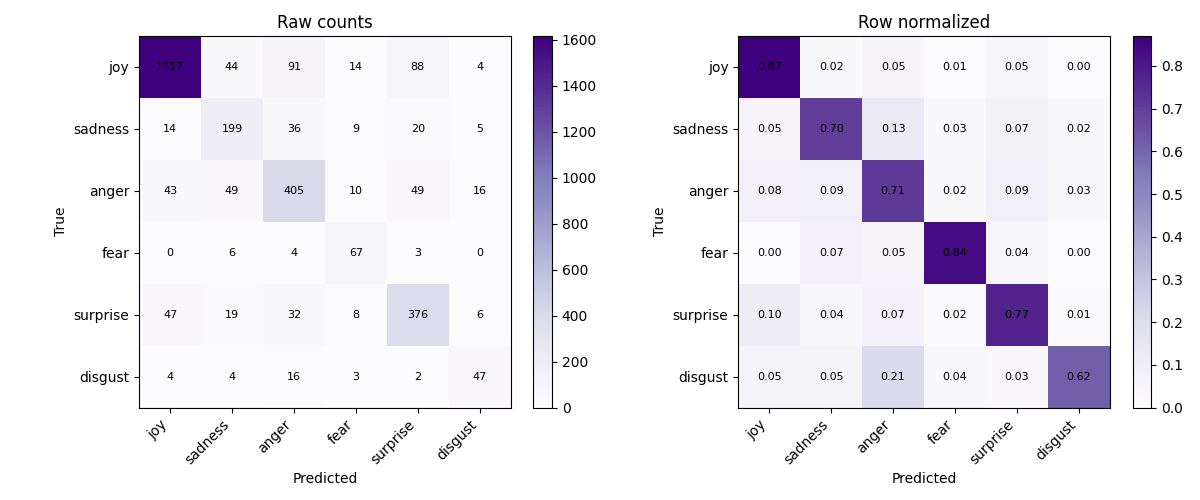

**BiLSTM + Attention: validation heatmaps.** The six class headings below are ground-truth labels, not claims of correct predictions. Each example reports the attention model's prediction and agreement or disagreement with the selected classifier. Colors show actual normalized token weights, not causal word importance.

<HTML display>

**Findings.** distilbert achieved 80.76% test accuracy and 0.7179 macro F1. BiLSTM + Attention exceeded LSTM by 3.26 macro-F1 percentage points, although directionality also differs, so this does not isolate attention's contribution. For the selected model, joy F1 was 0.9026, sadness F1 0.6589, and disgust F1 0.6104. Fear and disgust have only 80 and 76 test examples, respectively. Scores describe the filtered, single-label English Reddit subset; neutral and mixed emotions were excluded. Probabilities are uncalibrated, and attention is an inspection aid. Test outcomes do not change the validation-selected winner.

In [ ]:
# Display recorded artifacts only: no training, model loading, or test evaluation.
import csv, io, json, pathlib, zipfile
from IPython.display import display, Markdown, HTML, Image

report_dir = pathlib.Path(BASE) / "reports"
if (report_dir / "model_comparison.csv").is_file() and (report_dir / "selection.json").is_file():
    def report_bytes(name):
        return (report_dir / name).read_bytes()
    evidence_source = "Current run reports"
else:
    roots = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    candidates = [candidate for root in roots for candidate in (
        root / "codex-space/emotion_reports.zip",
        root / "Sprint03-NLP/Project03-Emotion_Classification_with_Attention/codex-space/emotion_reports.zip",
    )]
    archive_path = next((candidate for candidate in candidates if candidate.is_file()), None)
    if archive_path is None:
        raise FileNotFoundError("Run the delivery stage first, or keep codex-space/emotion_reports.zip beside the project notebooks folder.")
    def report_bytes(name):
        with zipfile.ZipFile(archive_path) as archive:
            return archive.read(name)
    evidence_source = "Saved full-run reports archive (historical training evidence)"

comparison = list(csv.DictReader(io.StringIO(report_bytes("model_comparison.csv").decode("utf-8"))))
selection = json.loads(report_bytes("selection.json"))
selected = selection["selected"]
full = selection["mode"] == "full"
has_test = full and all(row.get("test_macro_f1") for row in comparison)
def score(value):
    return f"{float(value):.4f}" if value else "—"
table = ["| Model | Validation accuracy | Validation macro F1 | Test accuracy | Test macro F1 | Best epoch |",
         "|---|---:|---:|---:|---:|---:|"]
for row in comparison:
    name = ("**" + row["model"] + " (selected)**") if row["model"] == selected else row["model"]
    table.append("| " + " | ".join([name, score(row["validation_accuracy"]), score(row["validation_macro_f1"]),
        score(row.get("test_accuracy")) if has_test else "—", score(row.get("test_macro_f1")) if has_test else "—",
        str(int(float(row["best_epoch"])))]) + " |")
display(Markdown("**Evidence:** " + evidence_source + ". All scores below use a 0–1 scale.\n\n" + "\n".join(table)))
display(Markdown(f"**Selected classifier: {selected}.** Selection used validation macro F1 and was frozen before held-out evaluation. "
    + selection["tie_policy"] + " The main prediction and confidence bars belong to the selected classifier; "
    "the attention view belongs to BiLSTM + Attention and shows that model's own prediction."))
if has_test:
    display(Markdown("**Selected model: held-out confusion matrices.** Left: raw counts; right: row-normalized values."))
    display(Image(data=report_bytes(f"final_test/{selected}/{selected}_confusion.png")))
else:
    display(Markdown("**Functional smoke/bounded run:** no real test metrics are displayed. The following matrices concern validation only."))
    display(Image(data=report_bytes(f"{selected}_validation_confusion.png")))
display(Markdown("**BiLSTM + Attention: validation heatmaps.** The six class headings below are ground-truth labels, "
    "not claims of correct predictions. Each example reports the attention model's prediction and agreement or disagreement "
    "with the selected classifier. Colors show actual normalized token weights, not causal word importance."))
display(HTML(report_bytes("attention_examples.html").decode("utf-8")))
if has_test:
    metrics = json.loads(report_bytes(f"final_test/{selected}/metrics.json"))
    per_class = metrics["classification_report"]
    by_model = {row["model"]: row for row in comparison}
    attention_gain = float(by_model["bilstm_attention"]["test_macro_f1"]) - float(by_model["lstm"]["test_macro_f1"])
    display(Markdown(
        f"**Findings.** {selected} achieved {metrics['accuracy']:.2%} test accuracy and {metrics['macro_f1']:.4f} macro F1. "
        f"BiLSTM + Attention exceeded LSTM by {attention_gain * 100:.2f} macro-F1 percentage points, although directionality "
        "also differs, so this does not isolate attention's contribution. "
        f"For the selected model, joy F1 was {per_class['joy']['f1-score']:.4f}, sadness F1 {per_class['sadness']['f1-score']:.4f}, "
        f"and disgust F1 {per_class['disgust']['f1-score']:.4f}. Fear and disgust have only "
        f"{int(per_class['fear']['support'])} and {int(per_class['disgust']['support'])} test examples, respectively. "
        "Scores describe the filtered, single-label English Reddit subset; neutral and mixed emotions were excluded. "
        "Probabilities are uncalibrated, and attention is an inspection aid. Test outcomes do not change the validation-selected winner."
    ))
else:
    display(Markdown("**Findings.** This is a functional smoke/bounded run. Its tiny validation scores do not establish model quality; the real test set was not predictively evaluated."))
